# **Ant Project Notebook**
***
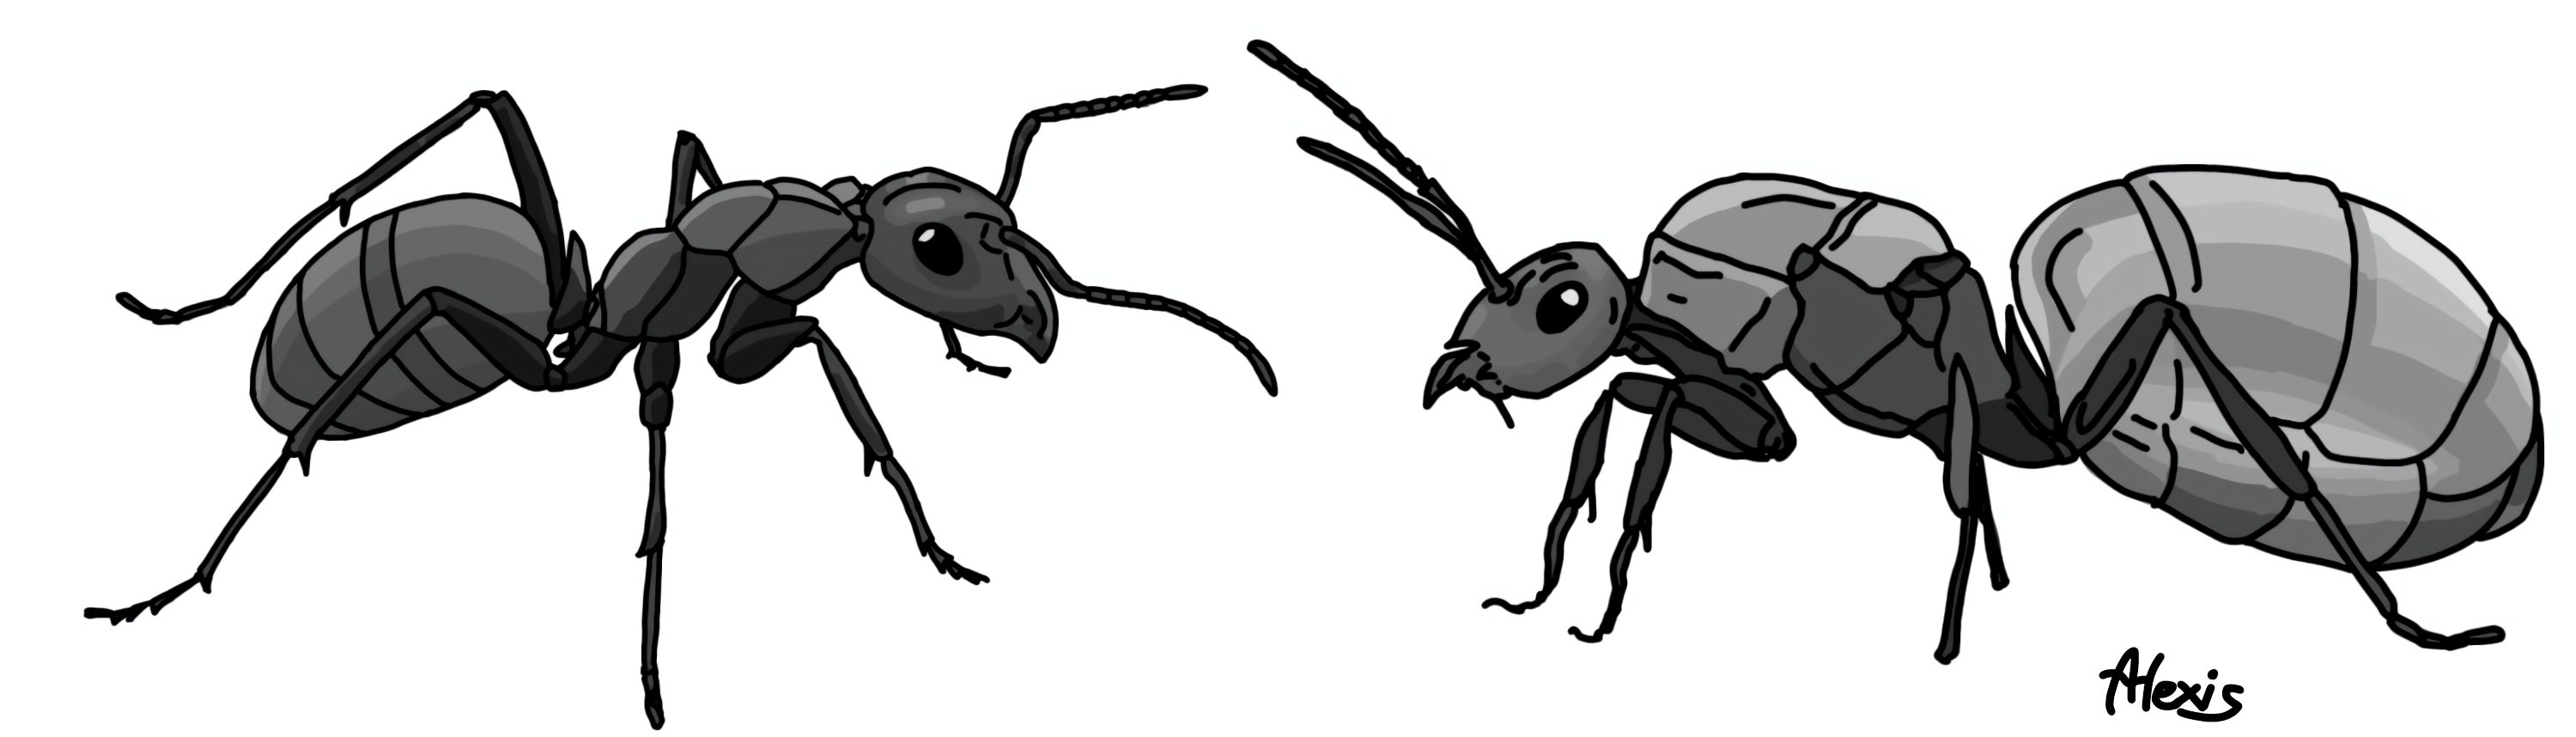
***

### **Import Useful Libraries, Script and Seed**
Just, below we imported all the useful libraries and custom script `ant_dataset_generator.py`:

In [374]:
### --- Libraries for General Use --- ###
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

### --- Libraries for Adaptative Data Loading ---
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

### --- Loading Script for Data Generation --- ###
if IN_COLAB and not os.path.exists('ant_dataset_generator.py'):
    !wget https://raw.githubusercontent.com/EnvinyatarTheRenewer/ant_life_cycle_simulation_and_ml/main/ant_dataset_generator.py
# This custom script generates data based on random sampling of each features within their biological range.

### --- Libraries to Hide Warnings --- ###
import warnings
from sklearn.exceptions import DataConversionWarning
warnings.filterwarnings(action = 'ignore', category = DataConversionWarning)
warnings.filterwarnings(action = 'ignore', category = UserWarning)

### --- Libraries for Data Transformation --- ###
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

### --- Libraries for Models' Hyperparameters Tuning --- ###
from sklearn.model_selection import RandomizedSearchCV

### --- Libraries for Logistic Regression --- ###
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, roc_auc_score, 
                             roc_curve, confusion_matrix)

### --- Libraries for Decision Tree --- ###
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

### --- Libraries for Random Forest --- ###
from sklearn.ensemble import RandomForestClassifier

### --- Libraries for XGBoost --- ###
from xgboost import XGBClassifier

### --- Libraries for Neural Networks --- ###
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance

### --- Random Seed --- ###
random_seed = 5

### **Creating Helper Plotting Functions for the Subsequent Parts**

*In the cell below, we created two helper functions called `plot_feature_distr` and `plot_feature_pairwise_corr`.*

1. **`barplot_polymorphic_or_not`:** This helper function plots a barplot displaying the polymorphic fraction against the non polymorphic fraction.
2. **`plot_feature_distr`:** This helper function helps to plot the non polymorphic and polymorphic distribution separately for each features and make a grouped figure.
3. **`plot_feature_pairwise_corr`:** This helper function helps to plot the corroleation matrix of all the features and response variable.
4. **`plot_confusion_matrix`:** This helper function, given a model and data set (training, validation or test), helps display the confusion matrix of the model.
5. **`plot_roc`:** This helper function, given a model and data set (training, validation or test), plots the ROC and AUC.
6. **`feat_imp_plot`:** This helper function, given a model, a preprocessor (or pipeline) and a model name, displays the feature importance plot.

In [375]:
### --- Polymorphic Versus Non Polymorphic Barplot Helper --- ###
def barplot_polymorphic_or_not(df, polymorph_treshold = 0.0):
       # Note on polymorph_treshold=0.0:
       # This treshold is the minimum percentage of cases 
       # required for us to consider that there is some 
       # polymorphism. Here anything that displayed at 
       # least a replicate with the allele maintained was 
       # considered maintaing polymorphism. Feel free to play
       # with it a bit.

       # Identify all the polymorphic cases
       polymorph_samples = (df['frac_polymorphic'] > polymorph_treshold)

       # Create the barplot of the non-polymorphic vs polymorphic fraction.
       fig, ax = plt.subplots()             # Creates the barplot.
       ax.bar([0, 1], [1 - polymorph_samples.mean().item(), polymorph_samples.mean().item()], 
              color='skyblue')              # Display the two bars.
       ax.set_xticks(ticks = [0, 1], labels = ['Non Polymorphic', 'Polymorphic']) # Set axis x.
       ax.set_ylabel('Fraction of Samples') # Set axis y and below title.
       ax.set_title('Non-Polymorphic vs Polymorphic Fraction', fontweight = 'bold', pad = 15)
       # Display plot.
       plt.show()

### --- Features Distribution Plotting Helper Function --- ###
def plot_feature_distr(df, params, polymorph_treshold = 0.0):
  polymorph_samples = (df['frac_polymorphic'] > polymorph_treshold) # Separating the non polymorphic versus 
                                                                    # polymorphic sample.
  fig, axs = plt.subplots(nrows = 3, ncols = 4, figsize = (15, 12)) # Figure shape and size.
  for i, col_name in enumerate(params): # Iterating for each parameters and plotting its distribution.
      ax = axs[i // 4, i % 4]
      # Plotting the non polymorphic and polymorphic distribution separately on the same plot.
      ax.hist(df[polymorph_samples][col_name], bins = 20, alpha = 0.5, label = 'Polymorphic', density = True)
      ax.hist(df[~polymorph_samples][col_name], bins = 20, alpha = 0.5, label = 'Non Polymorphic', density = True)
      ax.set_title(col_name, fontweight = 'bold')
      ax.set_xlabel('Value') 
      ax.set_ylabel('Frequency')
  handles, labels = ax.get_legend_handles_labels()
  # Adding the rest of the legend.
  fig.legend(handles, labels, bbox_to_anchor = [0.97, 0.2], fontsize = 18)
  fig.delaxes(axs[-1][-1])
  plt.tight_layout()
  plt.show()

### --- Plotting Correlation Table Helper Function --- ###
def plot_feature_pairwise_corr(df):
  corr_matrix = df.corr() # Obtain the correlation table.
  # Plot and display the correlation table with title and label.
  fig, ax = plt.subplots(figsize = (10, 8))
  cax = ax.matshow(corr_matrix, cmap = 'PuOr', vmin = -1, vmax = 1)
  ax.set_xticks(range(len(corr_matrix.columns)))
  ax.set_yticks(range(len(corr_matrix.columns)))
  ax.set_xticklabels(corr_matrix.columns, rotation = 90)
  ax.set_yticklabels(corr_matrix.columns)
  fig.colorbar(cax)

### --- Plotting the Confusion Matrix Helper Function --- ###
def plot_confusion_matrix(model, X_set, y_set, type_of_set = "Test"):
    # Plots a custom confusion matrix with TN, FP, FN, TP (%) labels and colormap.
    cm = confusion_matrix(y_set, model.predict(X_set)) 
    total = cm.sum()
    cm_percent = (cm / total) * 100
    TN_p, FP_p, FN_p, TP_p = cm_percent.ravel()

    # Add the annotations.
    annot_labels = np.array([
        [f'True Negative (TN)\n{TN_p:.1f}%', f'False Positive (FP)\n{FP_p:.1f}%'],
        [f'False Negative (FN)\n{FN_p:.1f}%', f'True Positive (TP)\n{TP_p:.1f}%']
    ])

    # Plotting the confusion matrix, with labels and title.
    plt.figure(figsize = (7, 6))
    sns.heatmap(cm_percent, annot = annot_labels, fmt = '', cmap = 'Oranges', cbar = True, 
                linewidths = 2, annot_kws = {'size': 12, 'weight': 'bold'},
                vmin = 0, vmax = 100)
    plt.title(f'Confusion Matrix of the {type_of_set} Set', fontsize = 14, fontweight = 'bold', pad = 15)
    plt.xlabel('Predicted Label', fontsize = 12)
    plt.ylabel('True Label', fontsize = 12)
    plt.show()

### --- Plotting the ROC Helper Function --- ###
def plot_roc(model, X_set, y_set, type_of_set = "Test"):
    # Plots the ROC curve with sky-blue AUC fill and orange curve line.
    # Calculate the false positive rate and the true positive rate.
    y_test_proba = model.predict_proba(X_set)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_set, y_test_proba)
    auc_score = roc_auc_score(y_set, y_test_proba)

    # Plot the figure.
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color = 'orange', lw = 2, label = 'ROC Curve')
    plt.plot([0, 1], [0, 1], color = 'gray', linestyle = '--')
    plt.fill_between(fpr, tpr, color = 'skyblue', alpha = 0.4, label = f'AUC (={auc_score:.3f})')

    # Add the legend, label and title.
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.title(f'Receiver Operating Characteristic (ROC) for the {type_of_set} Set', fontsize = 14, 
              fontweight = 'bold', pad = 15)
    plt.xlabel('False Positive Rate', fontsize = 12)
    plt.ylabel('True Positive Rate', fontsize = 12)
    plt.legend(loc = 'lower right')
    plt.grid(alpha = 0.3)
    plt.show()

### --- Plotting Feature Importance Helper Function --- ###
def feat_imp_plot(preprocess, model, model_name):
    # ct is your preprocessor or pipeline and model your model 
    # for which you want the feature importance (RF, XGB, MLP).
    # Extract feature names from your preprocessor.
    feature_names = preprocess.get_feature_names_out()

    # Build the Series using the features' names.
    importances = pd.Series(model.feature_importances_, index = feature_names)

    # Plot the top 10 features, with title and labels.
    plt.figure(figsize = (10, 6))
    importances.nlargest(10).sort_values().plot(kind = 'barh', color = 'moccasin')
    plt.title(f'Top 10 Feature Importances for {model_name}', fontweight = 'bold')
    plt.xlabel('Relative Importance')
    plt.ylabel('Features')
    plt.tight_layout()
    plt.show()

## **Data Generation Procedure**

*In this section, we explain how we generated the `.csv` data. For each feature we randomly generated a value within its biological range. Thus, each row in the generated `.csv` file represents a combination of all the randomly generated features (parameters' set) and the targets (what happened to the de novo rare allele over `reps` replicate simulations).*

<div class='alert alert-block alert-info'>
<b>Model in one paragraph:</b> A structured metapopulation of Nd (fixed to 100) ant colonies with Nq (1 to 10) queens each; de novo allele (freshly appeared in the population) starts in ic (fixed to 20) colonies. The queen and the workers have their own optimum, respectively 1 and 0. The parameter z represents the actual fitness (0 to 1), or how close we are to the worker and queen optimum. Additionally, we have the allele effect s (-0.1 to 0.1, same for both) and dominance d; performance is 1 - (trait - z)^2. Finally, we track the allelic change of the de novo allele over T (fixed to 10'000) generation.
</div>

The other parameters used in the ants life cycle simulation are:

1. **Nm:** *number of reproductive males, ranges from 1 to 20.*
2. **s:** *survival rate, each ranges from 0.0 to 1.0.*
3. **e:** *extinction rate, each ranges from 0.0 to 1.0.*
4. **m:** *migration rate, each ranges from 0.0 to 1.0.*
5. **dq:** *dominance in the queens, each ranges from 0.0 to 1.0.*
6. **dw:** *dominance in the workers, each ranges from 0.0 to 1.0.*

For every tested value, we stored the following:
1. **all the features value used**
2. **n_reps:** *corresponds to the number of replicate for each features' set and was kept the same during the whole data generation (here it was fixed to a 100).*
3. **mean_pA:** *it is the mean allelic frequency, resulting from the arithmetic mean of each replicates' allelic frequency.*
4. **sd_pA:** *it is the standard deviation of the mean allelic frequency.*
5. **frac_lost:** *percentage of the replicates where the rare de novo allele was lost.*
6. **frac_fixed:** *percentage of the replicates where the rare de novo allele was fixed.*
7. **frac_polymorphic:** *percentage of the replicates where the rare de novo allele was neither fixed nor lost.*

<div class='alert alert-block alert-info'>
<b>Setup:</b> Keep ant_dataset_generator.py and ant_ml_dataset.csv in the same folder as this notebook if you are working locally. If you are working on collab it does not matter.
</div>

### **Figure 1: Life Cycle Simulation Schematics**
***
![Sans titre.jpg](<attachment:Sans titre.jpg>)
***

#### **Figure 1 Explanation:**
*Here is the full ant life cycle we modeled, happening for Nd deems (ant colonies), it’s the ecological backbone of the simulation. Let's go trough it quickly: colonies can either survive or go extinct. Then, surviving colonies first produce workers, and later sexuals. Once, the sexual are produced they need to mate, which can either happen locally or during a mating flights and occurs with Nm mating males.*

- *Survival correspond to the probability of queen that just reproduced to survive another cycle.*
- *Dispersal correspond to the probability of a local queen or another queen issued from dispersal to recolonize an empty queen slot.*

*Eventually, recolonization occurs and fill all the queen’s slots left empty from the queen’s death due to survival or deme extinction. With this ecological foundation in place, we can now connect genotype to phenotype and see how alleles actually affect queens and workers.*

### **Figure 2: Queen and Workers Phenotype/Genotypes:**
***
![Capture d’écran 2026-10-30 à 18.40.58.png](<attachment:Capture d’écran 2026-10-30 à 18.40.58.png>)
***

#### **Figure 2 Explanation:**
*In the model, we consider one focal diploid locus with two alleles, A (being the de novo allele) and a. These alleles have opposite effects in queens and workers, which then feed into colony fecundity and ultimately allele transmission.*

## **Data Loading**
Here, we loaded the data we previously generated, using the `ant_dataset_generator.py` script. Additionally, we removed some of the uninformative variables already (a bit of cleaning), among them:
1. **`frac_lost` and `frac_fixed`:** We removed them, as they are redundant with `frac_polymorphic`. Since, they are related by the following formula: <br> $1 -($`frac_lost`$+$`frac_fixed`$)=$`frac_polymorphic`
2. **`n_reps`:** It corresponds to the number of replicate for each features set and was kept identical during the whole data generation (here it was fixed to a 100). So, it does not vary.
3. **`mean_pA`:** The mean allelic frequency is a tricky response variable. What would one would expect when they see a mean allelic frequency of 0.5 is a high prevalence of polymorphism in most replicates. Whereas, what often happen is we have a high prevalence of fixed allele due to its positive effect on the fitness (`mean_pA`$=1$) and a high loss of the allele (`mean_pA`$=0$), simply due to stochastics. Thus without any polymorphism being maintained, we are observing an average `mean_pA` simply thanks to loss and fixation of the allele.
4. **`sd_pA`:** is simply the standard deviation of the mean allelic frequency after 10'000 generations. As we just explained, we saw that the mean allelic frequency is not a good metric. Thus, `sd_pA` is not a useful either.

<div class='alert alert-block alert-info'>
<b>[Optionnal]:</b> The commented code part in the cell below helps you generate the data again if you wish (account for about 5 days of runtime if run locally and 2 on collab). Else, you can use the ant_ml_dataset.csv instead, by putting it in the same folder if working locally (else if you are collab it does not matter).
</div>
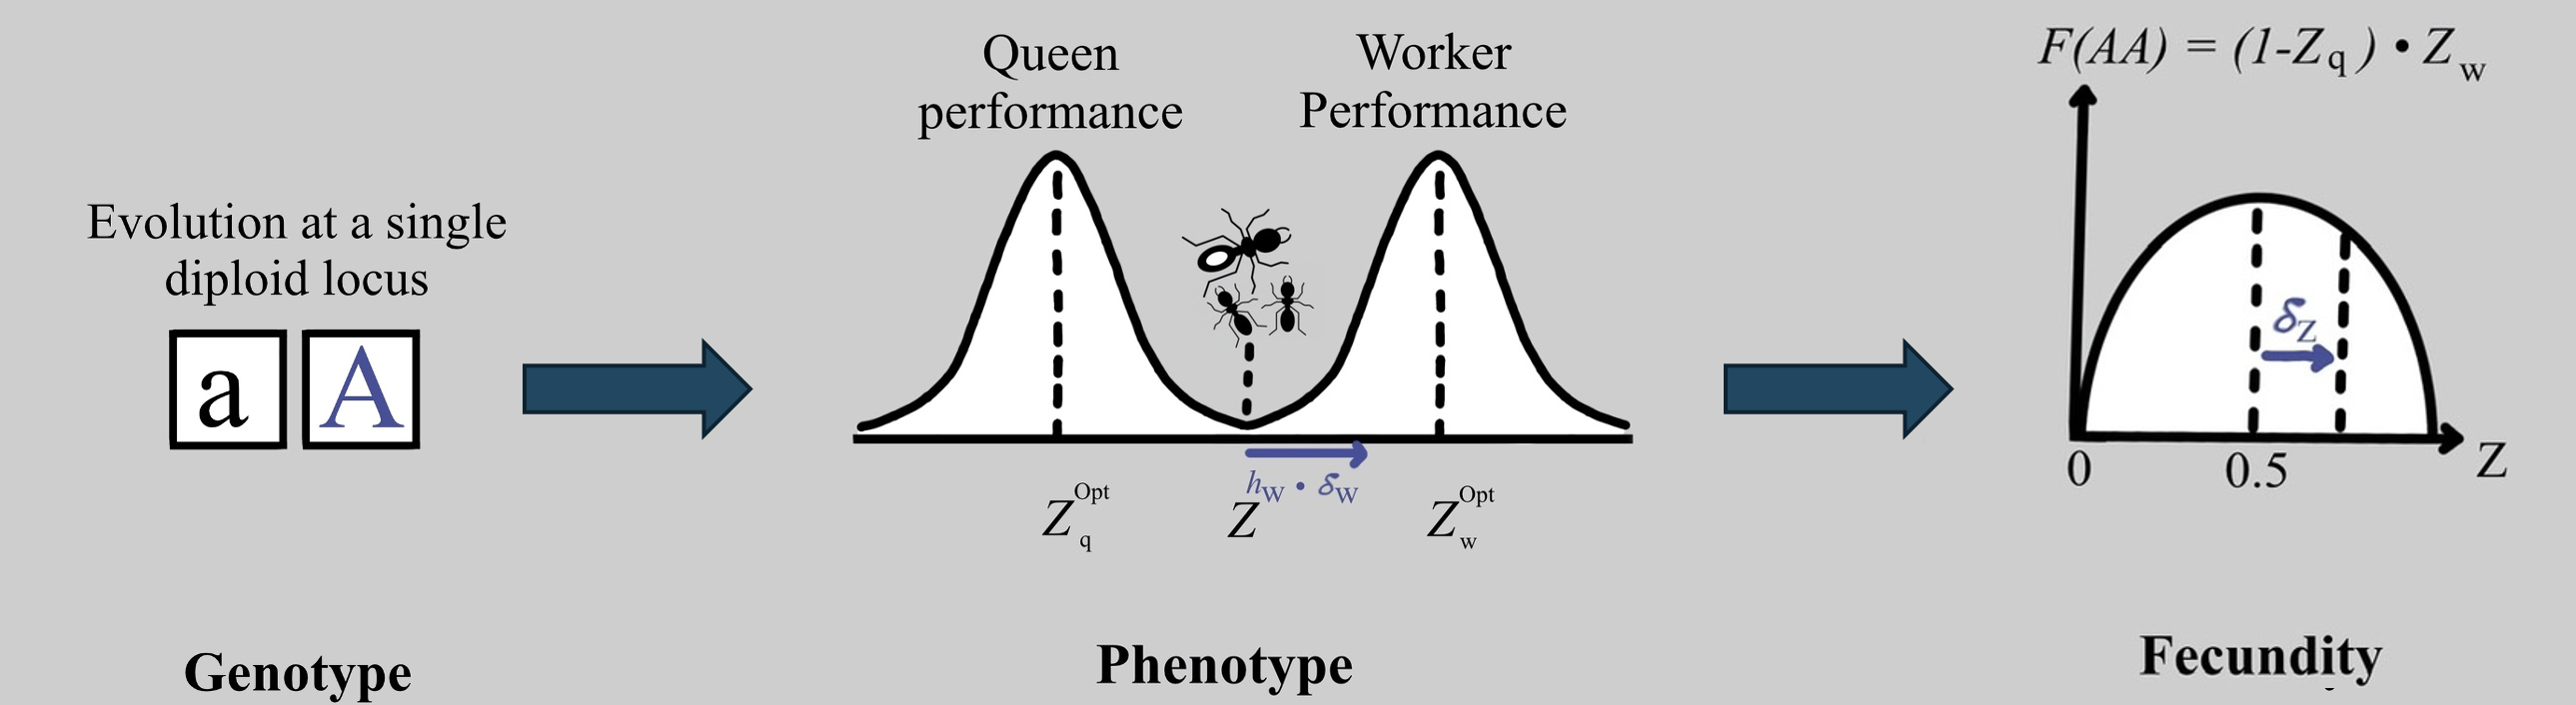
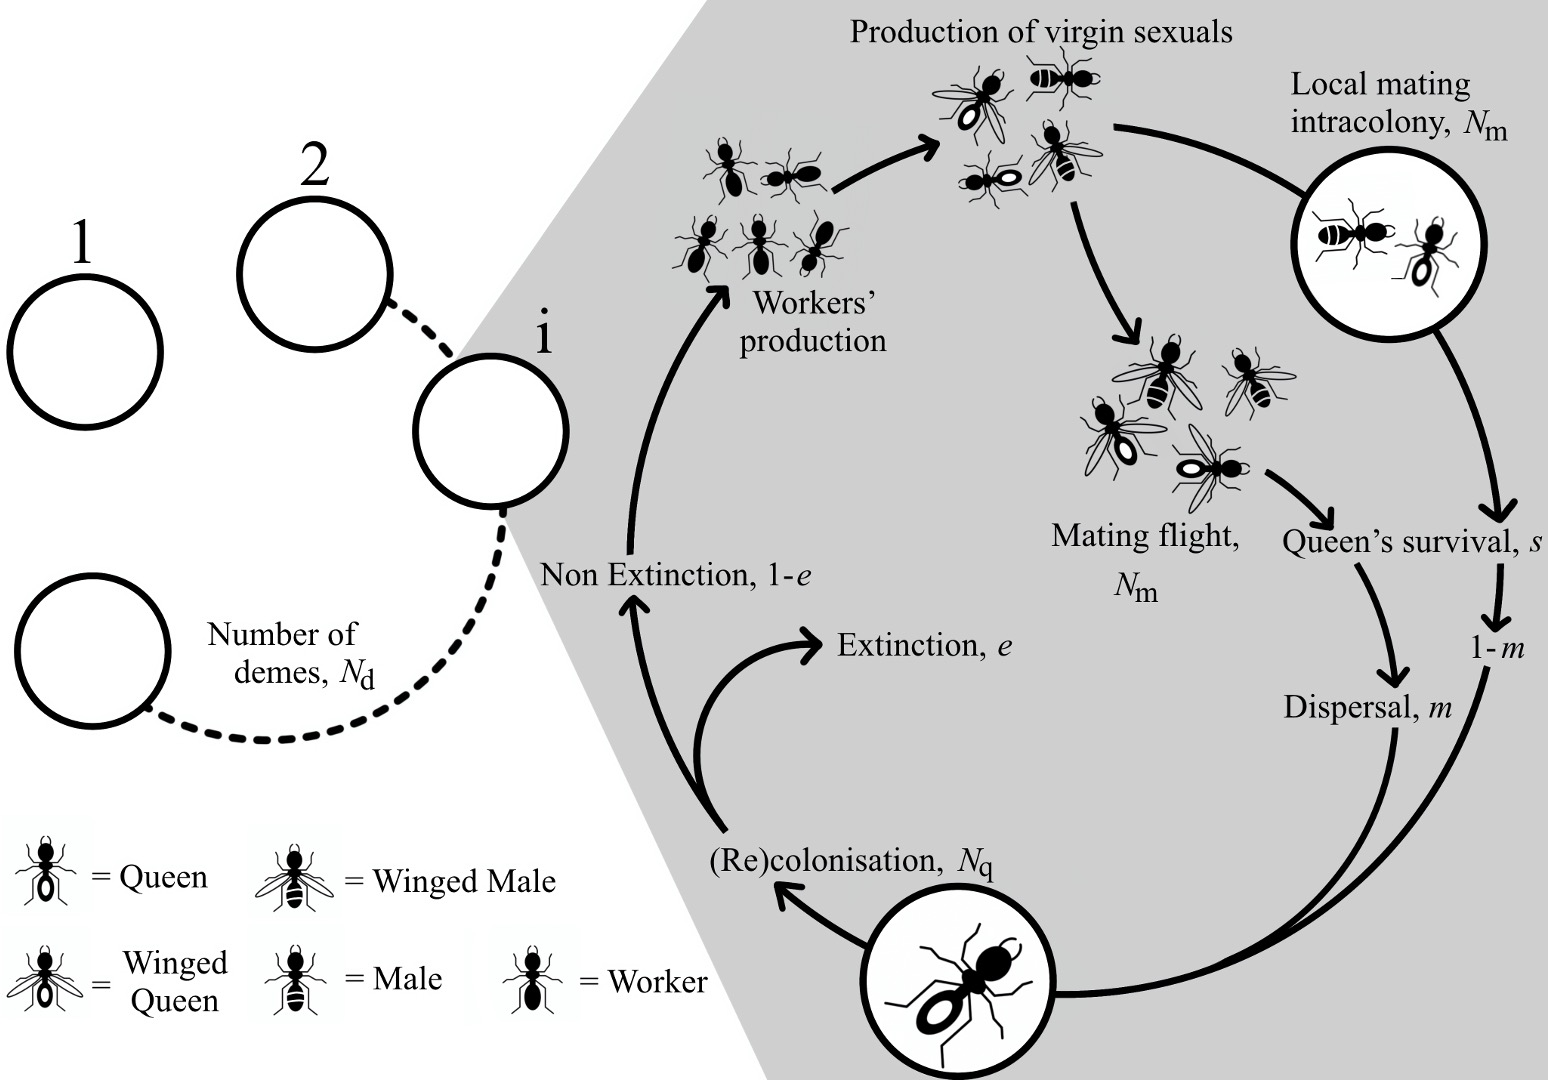

In [376]:
### --- Data Generation Using our Custom Data Generator --- ###
# error_or_not, msg = generate_dataset(n_samples=10000, reps=100, workers=4)
# print(msg)

### --- Data Loading (Adaptive for Local or Colab) --- ###
if IN_COLAB:
    print('Running in Google Colab: Fetching dataset from GitHub...')
    # Use the raw GitHub URL so Colab can download/read it directly without cloning.
    csv_url = 'https://raw.githubusercontent.com/EnvinyatarTheRenewer/ant_life_cycle_simulation_and_ml/main/ant_ml_dataset.csv'
    df = pd.read_csv(csv_url, index_col = 0)
else:
    print('Running locally: Reading dataset from local folder...')
    # Reads from your local directory where the script is saved.
    df = pd.read_csv('ant_ml_dataset.csv', index_col = 0)

### --- Data Cleaning --- ###
df.drop(['sd_pA', 'n_reps', 'frac_lost', 'frac_fixed', 'mean_pA'], axis = 1, inplace = True) # Get rid of what is irrelevant 
                                                                                             # (not explanatory variable or response 
                                                                                             # variable).

### --- Response Variable and Features --- ###
# Here we separate features from response variables.
params_cols = ['s', 'e', 'm', 'zw', 'zq', 'dw', 'dq', 'sw', 'sq', 'Nq', 'Nm'] # Store all features together.
result_cols = ['frac_polymorphic'] # Store the response variable alone.

Running locally: Reading dataset from local folder...


/var/folders/h6/9k3xyll50pld7y_xhy85yjzm0000gn/T/ipykernel_64795/3685363325.py:17: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(['sd_pA', 'n_reps', 'frac_lost', 'frac_fixed', 'mean_pA'], axis = 1, inplace = True) # Get rid of what is irrelevant


In [377]:
### --- Data Display --- ###
df.head(5) # Display head of the data.

,s,e,m,zw,zq,dw,dq,sw,sq,Nq,Nm,frac_polymorphic
sample_id,,,,,,,,,,,,
0,0.357718,0.230921,0.483966,0.314324,0.314324,0.806838,0.825209,0.065894,0.065894,8,2,0.00
3,0.048572,0.359939,0.239023,0.591418,0.591418,0.944899,0.173094,0.079700,0.079700,1,3,0.00
1,0.892589,0.479211,0.830789,0.885811,0.885811,0.740353,0.034923,-0.012227,-0.012227,3,7,0.00
5,0.072650,0.630431,0.530054,0.282026,0.282026,0.443350,0.346804,0.040918,0.040918,7,9,0.00
4,0.475356,0.660237,0.224082,0.257872,0.257872,0.115671,0.831151,-0.058153,-0.058153,3,9,0.26


## **Data Distribution Visualization**

Now, let's have a look at our data, so that we know **how to process it**. First, we plotted an **histogram displaying the distribution of our response variable** `frac_polymorphic` to see how our polymorphism is present in our data. For reminder, this variable represents how many cases of polymorphism are observed in percent among the replicates of one features' set. 

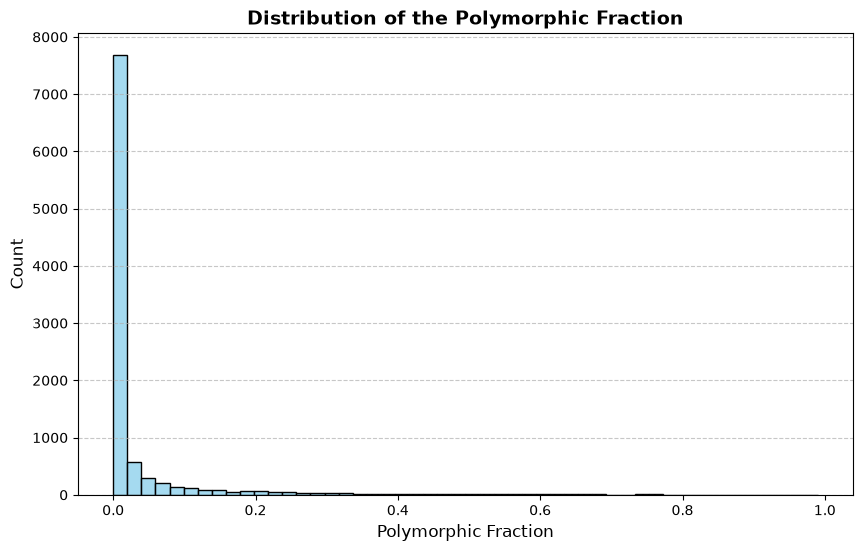

In [378]:
### --- Distribution of the Polymorphic Fraction --- ###
plt.figure(figsize = (10, 6)) # Set figure dimensions.
sns.histplot(df['frac_polymorphic'], bins = 50, color = 'skyblue') # Plots the histogram.

# Add labels, title and a horizontal dashed lines for clarity.
plt.title('Distribution of the Polymorphic Fraction', fontsize = 14, fontweight = 'bold' )
plt.xlabel('Polymorphic Fraction', fontsize = 12)
plt.ylabel('Count', fontsize = 12)
plt.grid(axis = 'y', linestyle = '--', alpha = 0.7)

# Displays plot.
plt.show()

## **Classification or Regression Task?**
### *What the data tells us...*
As we can see, our data displays the very classical **zero inflated distribution.** With this new information in mind, we can now discuss the best course of action to perform our task. 

Intially before knowing our data distribution, we could have **framed our problem in two manners.** Either a **regression task or a classification task**, both having a solid biological sense despite answering slightly different questions. The first would allow us **to quantify how this polymorphism frequence vary**. The second loses this variation interpretation **for a simpler binary classification** that is already biologically relevant, by telling us wether we observe polymorphism or not based of a given feature set.

Since our data is so skewed, if we were doing directly a regression task our model would focus to much on all the zero values and tend to predict that we more frequently see null values than in reality. So, a **more acceptable solution** is to do a **binary classification** after a balancing of the dataset with:
- **0:** Non Polymorphic
- **1:** Polymorphic

Biologically speaking, since we mostly care about wether we observe polymorphism or not. This trade off in quantification of the frequence variance is perfectly acceptable. Nonetheless, if later we decide that quantifying it comes to be relevant, we could very easily developp a **Hurdle model**. This could be achieved by **splitting the question in two separate consecutiv models**. First our classificator that establishes wether we see polymorphism or not. Then, we would use our regressor that is trained only on the polymorphic fraction to establish what frequency of polymorphism we expect to observe.

Now, let's see **how many cases are actually displaying some polymorphy in our randomly generated data**, since we wanna start with classification. For that we will use the `frac_polymorphic` variable and make a bar plot displaying on one side all the non null values (polymorphic) and on the other all the null values (non polymorphic).

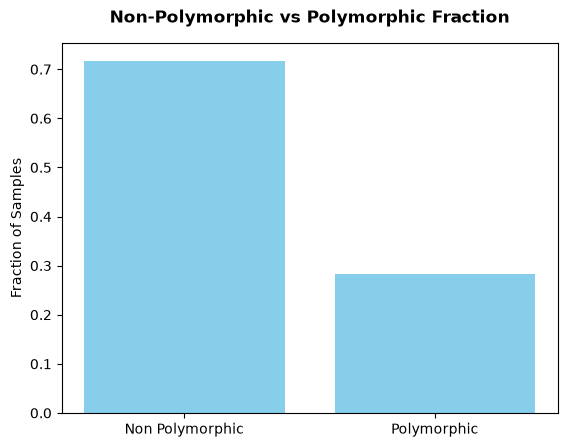

In [379]:
### --- Polymorphic Versus Non Polymorphic Barplot --- ###
barplot_polymorphic_or_not(df, polymorph_treshold = 0.0)

<div class='alert alert-block alert-info'>
<b>Non polymorphic versus polymorphic cases discussion:</b> As we can see, it seems that there is about 2.5 times more non polymorphic than polymorphic cases. Hence, it would be good to balance our data and remove part of the non polymorphic fraction to avoid introducing some biases in our learning. Yet first, we need to observe the current distribution of our features. That will allow us to make sure that the distribution of those remains identical after we eliminated part of our data.
</div>

### **Non Polymorphic and Polymorphic Distribution Plotted for each Features**
Here is the **distribution for each features** prior to the cut that we want to operate in the data. Those shall remain identical after we dropped part of the data.

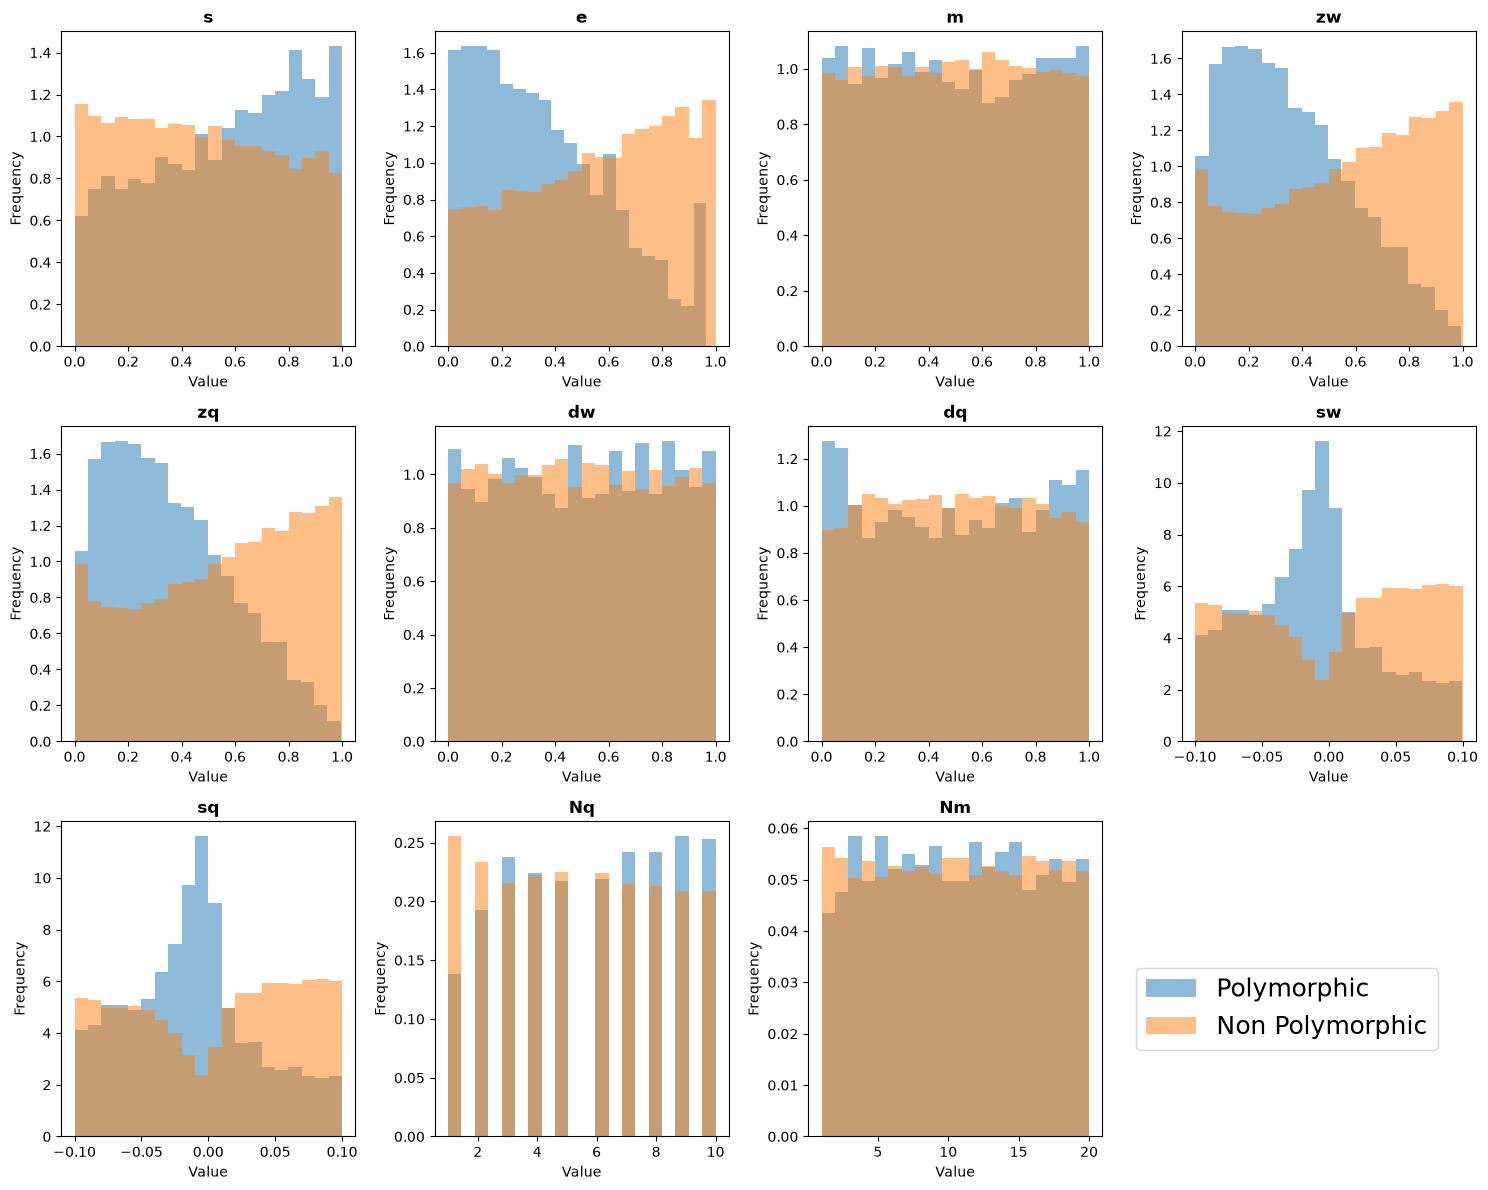

In [380]:
### --- Plotting Using the Helper plot_feature_distr --- ###
plot_feature_distr(df, params_cols)

### **Correlation Matrix of all the Features and our Response Variable**

Below we plotted the **correlation matrix of our data**. What we want to **avoid** is having **highly correlated features**. We already know that some are, by how the simulation is designed. We will wanna drop these to keep only one of them.

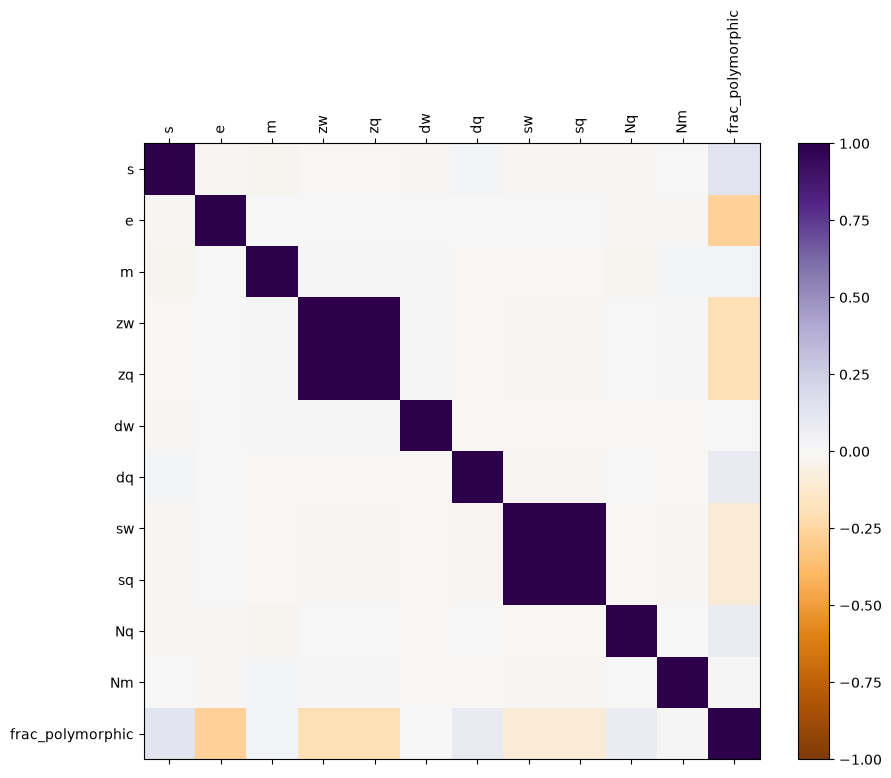

In [381]:
### --- Plotting Using the Helper plot_feature_pairwise_corr --- ###
plot_feature_pairwise_corr(df)

<div class='alert alert-block alert-info'>
<b>Data Distribution and Correlation:</b> As we can see, the only variable that are super correlated are Zq/Zw and Sw/Sq, which are correlated by design during the simulation. We will for each discard one of the two. As for the distribution, we need need to compare them once the cut has been operated.
</div>

## **Data Reduction**
Let's now **reduce** the **non polymorphic fraction** and **remove** our **correlated features**.

In [382]:
### --- Data Reduction --- ###
# Identify all the polymorphic cases
polymorph_treshold = 0.0
polymorph_samples = (df['frac_polymorphic'] > polymorph_treshold)
df_non_poly_thin = df[~polymorph_samples].sample(n = polymorph_samples.sum().item(), random_state = random_seed)
df_thin = pd.concat([df[polymorph_samples], df_non_poly_thin]) # Dropping part of 
                                                               # the non polymorphic.
# Remove the highly correlated features.                                                       
df_thin.drop(['zw', 'sw'], axis = 1, inplace = True) # Removing correlated features.
params_cols.remove('zw')
params_cols.remove('sw')

/var/folders/h6/9k3xyll50pld7y_xhy85yjzm0000gn/T/ipykernel_64795/4137519902.py:9: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_thin.drop(['zw', 'sw'], axis = 1, inplace = True) # Removing correlated features.


### **After Data Reduction**

In the code below, we check that our data is **still respecting its previous distribution for each features**, now that we equalized it. As we can see with `df_thin.describe().head(3)`, we have **5620 samples** once we operated our reduction.

In [383]:
### --- Displaying the Statistics of the New Data Frame --- ###
df_thin.describe().head(3)

,s,e,m,zq,dw,dq,sq,Nq,Nm,frac_polymorphic
count,5620.000000,5620.000000,5620.000000,5620.000000,5620.000000,5620.000000,5620.000000,5620.000000,5620.000000,5620.000000
mean,0.519169,0.458874,0.499033,0.458262,0.500111,0.498599,-0.003329,5.598932,10.531139,0.062496
std,0.290777,0.284664,0.289842,0.279189,0.288583,0.292536,0.055124,2.844990,5.761122,0.136305


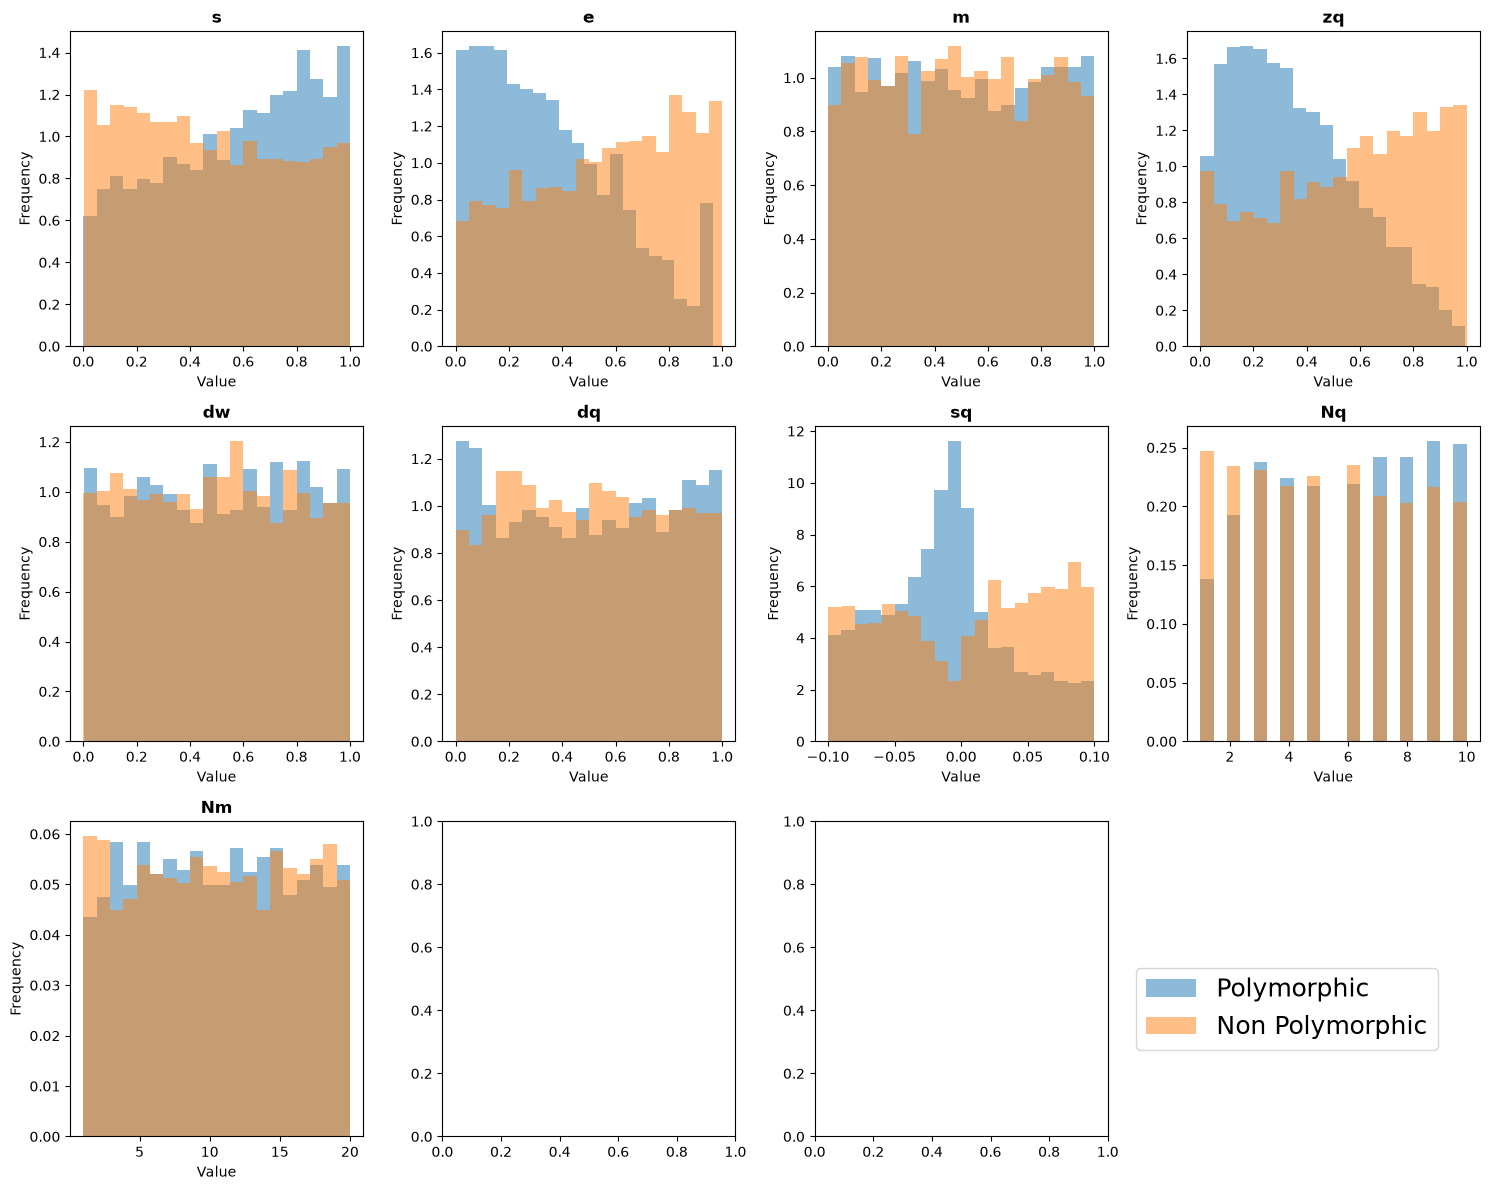

In [384]:
### --- Plotting Using the Helper plot_feature_distr  --- ###
plot_feature_distr(df_thin, params_cols)

<div class='alert alert-block alert-info'>
<b>Data Distribution:</b> Perfect, our distribution remain nearly perfectly identical. The two white boxes correspond to our two variables that we dropped.
</div>

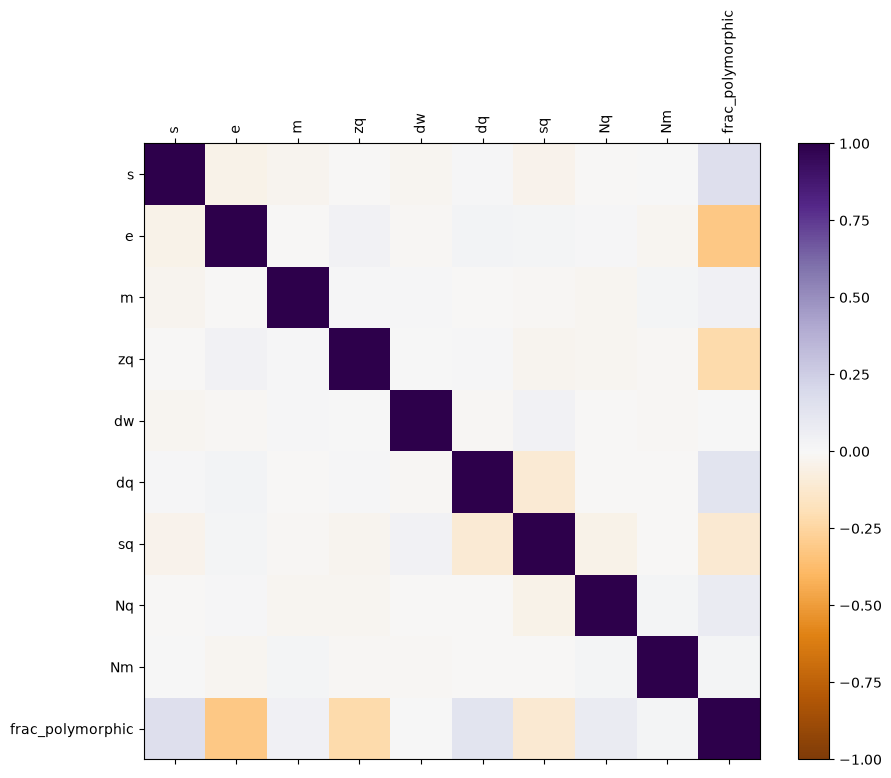

In [385]:
### --- Plotting Using the Helper plot_feature_pairwise_corr --- ###
plot_feature_pairwise_corr(df_thin)

<div class='alert alert-block alert-info'>
<b>Data Correlation:</b> Perfect, our data is no longer having highly correlated features.
</div>

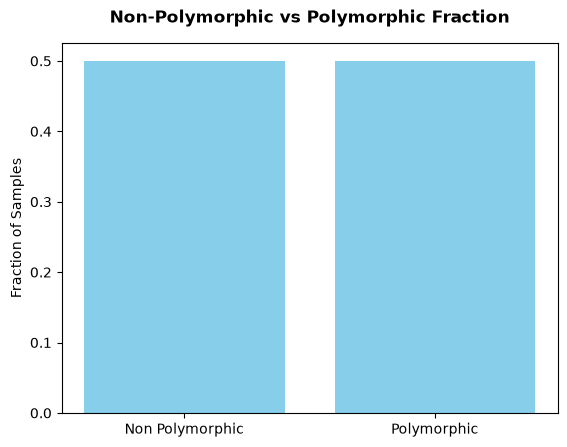

In [386]:
### --- Polymorphic Versus Non Polymorphic Barplot --- ###
barplot_polymorphic_or_not(df_thin, polymorph_treshold = 0.0)

<div class='alert alert-block alert-info'>
<b>Barplot verification:</b> As we can see, with the barplot: our data is now balanced.
</div>

## **Data Response Variable Correction**

Now, that we are sure that we **reduced our data correctly**, there is one last step to take it is simply to **change our `frac_polymorphic`** continuous variable into a binary variable called **`polymorphic`** for our classification task with:
- **0:** Non polymorphic
- **1:** Polymorphic

In [387]:
### --- Changing our Response Variable for Classification --- ###
# Addding our new column `Polymorphic` to our data frame.
df_thin['polymorphic'] = (df_thin['frac_polymorphic'] > 0.0).astype(int)
df_thin.drop(['frac_polymorphic'], axis = 1, inplace = True) # Removing our old variable.
result_cols = ['polymorphic'] # correcting our explanatory variable list.

# Displays our new equillibrate and ready to be preprocessed data.
df_thin.head(5)

/var/folders/h6/9k3xyll50pld7y_xhy85yjzm0000gn/T/ipykernel_64795/744223720.py:4: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_thin.drop(['frac_polymorphic'], axis = 1, inplace = True) # Removing our old variable.


,s,e,m,zq,dw,dq,sq,Nq,Nm,polymorphic
sample_id,,,,,,,,,,
4,0.475356,0.660237,0.224082,0.257872,0.115671,0.831151,-0.058153,3,9,1
6,0.950576,0.340998,0.824687,0.061601,0.879456,0.219170,0.038176,8,2,1
7,0.365080,0.745140,0.400069,0.189242,0.495235,0.494838,-0.042692,7,5,1
8,0.470395,0.663667,0.124523,0.064909,0.544222,0.424700,0.047439,4,18,1
19,0.968545,0.105871,0.410403,0.127432,0.333015,0.392471,0.060766,6,10,1


## **Split the Data**

We are splitting our data set of 5620 samples in the following manner:
- **Train set:** 90%
- **Validation Set:** 0% (Because, we will do some cross validation)
- **Test set:** 10%

In [388]:
### --- Variable and Features Separation for Handling --- ###
X = df_thin[params_cols]
y = df_thin[result_cols]

### --- Splitting the Data between Train, Validation and Test Sets --- ###
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.1, random_state = 1)

## **Preprocessing the Data**

Here are all the features used in the ants life cycle simulation:

1. **Nq:** *number of queens per deems, ranges from 1 to 10 **&#8594;** requires a transformation: **encoding in categorical variable.***
2. **Nm:** *number of reproductive males, ranges from 1 to 20 **&#8594;** requires a transformation: **encoding in categorical variable.***
3. **s:** *survival rate, each ranges from 0.0 to 1.0 **&#8594;** requires no transformation.*
4. **e:** *extinction rate, each ranges from 0.0 to 1.0 **&#8594;** requires no transformation.*
5. **m:** *migration rate, each ranges from 0.0 to 1.0 **&#8594;** requires no transformation.*
6. **dq:** *dominance in the queens, each ranges from 0.0 to 1.0 **&#8594;** requires no transformation.*
7. **dw:** *dominance in the workers, each ranges from 0.0 to 1.0 **&#8594;** requires no transformation.*
8. **zq(=zw):** *current level fitness of the classes, ranges from 0 (workers' optimum) to 1 (queens' optimum) **&#8594;** requires no transformation.*
9. **sq(=sw):** *mutation effect, ranges from -0.1 (workers' favorable) to +0.1 (queens' favorable) **&#8594;** requires a transformation: **scaling from 0 to 1.***


In [389]:
### --- Data Preprocessing --- ###
scale_cols = ['sq'] # Column to scale.
cat_cols = ['Nq', 'Nm'] # Column that are categorical.

# Transformer Creation
ct = ColumnTransformer(
    [('one_hot', OneHotEncoder(), cat_cols),
     ('scaled', MinMaxScaler(feature_range = (0, 1)), scale_cols)],
    remainder = 'passthrough')

# Data Transformation
X_train = ct.fit_transform(X_train)
X_test = ct.transform(X_test)

<div class='alert alert-block alert-info'>
<b>Data Preprocessing:</b> Now, our data is ready to be used for our machine learning!!
</div>

## **Logistic Regression**
Now that our data is ready for our classification task. Let's start simple and do a **logistic regression** to start. Below, we tried to **tune the hyperparameter C** (reducing regularization), which is the only tunable hyperparameter of this model. We obtained a **73 % accuracy** on the test set, which is not too bad! Seems like there is not much more than we can do except **visualize how well our model performs** in a more detailed manner and then try a **nonlinear model.**

In [390]:
### --- Best Logistic Regression Model --- ###

### --- Hyperparameter Tuning --- ###
# Define the parameter grid (only param C).
hyp_param = dict(C= [0.001, 0.01, 0.1, 1.0])

# Initialize the base model.
log_reg_model = LogisticRegression(random_state = random_seed, max_iter = 1000)

# Let's randomly search the hyperparameter space.
grid_search = RandomizedSearchCV(
    estimator=log_reg_model, 
    param_distributions=hyp_param, 
    cv=5,                       # cv=5 means 5-fold cross-validation on your training data.
    scoring='accuracy'          # scoring='accuracy' optimizes for accuracy.
)

# Fit the random search.
search = grid_search.fit(X_train, y_train)
best_C = grid_search.best_params_['C']           # Best C hyperparameter.
best_log_reg_model = grid_search.best_estimator_ # Object containing the best logistic 
                                                 # regression model.

### --- Accuracies on Train, Cross-Validation, and Test Sets --- ###
train_acc = accuracy_score(y_train, best_log_reg_model.predict(X_train)) # Whole traing set accuracy.
CVval_acc = search.best_score_                                           # Best cross validation accuracy.
test_acc = accuracy_score(y_test, best_log_reg_model.predict(X_test))    # Testing set accuracy.

print(f'--- Set Accuracies (for Best C: {best_C}) ---')
print(f'Train Accuracy:                   {train_acc:.4f}')
print(f'Cross-Validation Accuracy:        {CVval_acc:.4f}')
print(f'Test Accuracy:                    {test_acc:.4f}\n')

--- Set Accuracies (for Best C: 1.0) ---
Train Accuracy:                   0.7426
Cross-Validation Accuracy:        0.7370
Test Accuracy:                    0.7456



### Confusion Matrix

Let's plot our models confusion matrix.

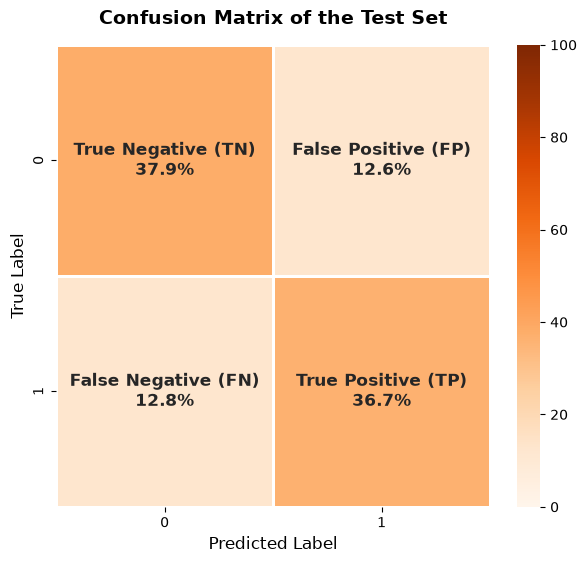

In [391]:
### --- Confusion Matrix for Logistic Regression --- ###
plot_confusion_matrix(model = best_log_reg_model, X_set = X_test, y_set = y_test, type_of_set = "Test")

We can see that we are right **a bit less than three times out of four** with our **logistic regression**, whereas if we were going by pure luck we would be wrong one time out two... Yet, there is much that we can improve.

### **ROC Plotting**
Let's see the **ROC** now! It shows the **trade off between recall and precision.** 

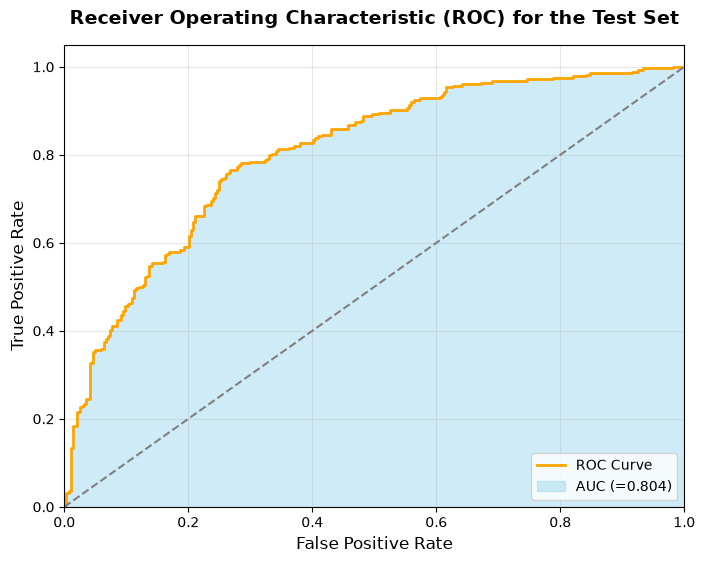

In [392]:
### --- ROC Curve for Logistic Regression --- ###
plot_roc(model = best_log_reg_model, X_set = X_test, y_set = y_test, type_of_set = "Test")

<div class='alert alert-block alert-info'>
<b>Logistic Regression Synthesis:</b> Despite a decent first accuracy with the logistic regression, we still have a solid margin to progress. Thus, we probably are dealing with some non linear relationship. Let's explore this with a decision tree.
</div>

## **Decision Tree**

Let's now fit directly a **tuned decision tree** using cross validation, since they **tend to overfit** (*a default decision tree was tried and overfit as expected*). With a bit of search, we found the **most reasonable hyperparameter ranges**. Additionally, we **pruned the tree** (`ccp_alpha =0.006`) to make it **more readable** without loosing accuracy. The **final accuracy** that we obtained the test set was of **80%** after reducing the overfit.

In [393]:
### --- Best Decision Tree --- ###

### --- Hyperparameter Tuning --- ###
# Here is the hyperparameter space we found 
# was appropriate to reduce overfitting.
hyp_params = dict(
    max_depth = range(1, 20),
    min_samples_leaf = range(5, 20),
    max_features = [None, 'sqrt', 'log2'],
    criterion = ['gini', 'entropy']
)

# Let's randomly search the hyperparameter space.
dt_opt = RandomizedSearchCV(
    DecisionTreeClassifier(random_state = random_seed, ccp_alpha = 0.006), 
    hyp_params, 
    random_state = 0, 
    cv = 10, 
    scoring = 'accuracy'
)

# Fit the random search.
print("------ Running Randomized Search for Decision Tree ------")
search = dt_opt.fit(X_train, y_train['polymorphic'])
best_model_dt = search.best_estimator_                  # Best model.
best_dt_params = search.best_params_                    # Best hyperparameter set.
print(f"\nBest Hyperparameters Found: {best_dt_params}\n")

### --- Accuracies on Train, Cross-Validation, and Test Sets --- ###
train_acc = accuracy_score(y_train, best_model_dt.predict(X_train)) # Whole traing set accuracy.
CVval_acc = search.best_score_                                      # Best cross validation accuracy.
test_acc = accuracy_score(y_test, best_model_dt.predict(X_test))    # Testing set accuracy.

print('------ Set Accuracies for DT ------')
print(f'Train Accuracy:              {train_acc:.4f}')
print(f'Cross-validation Accuracy:   {CVval_acc:.4f}')
print(f'Test Accuracy:               {test_acc:.4f}\n')

------ Running Randomized Search for Decision Tree ------

Best Hyperparameters Found: {'min_samples_leaf': 6, 'max_features': None, 'max_depth': 9, 'criterion': 'entropy'}

------ Set Accuracies for DT ------
Train Accuracy:              0.8074
Cross-validation Accuracy:   0.7865
Test Accuracy:               0.8060



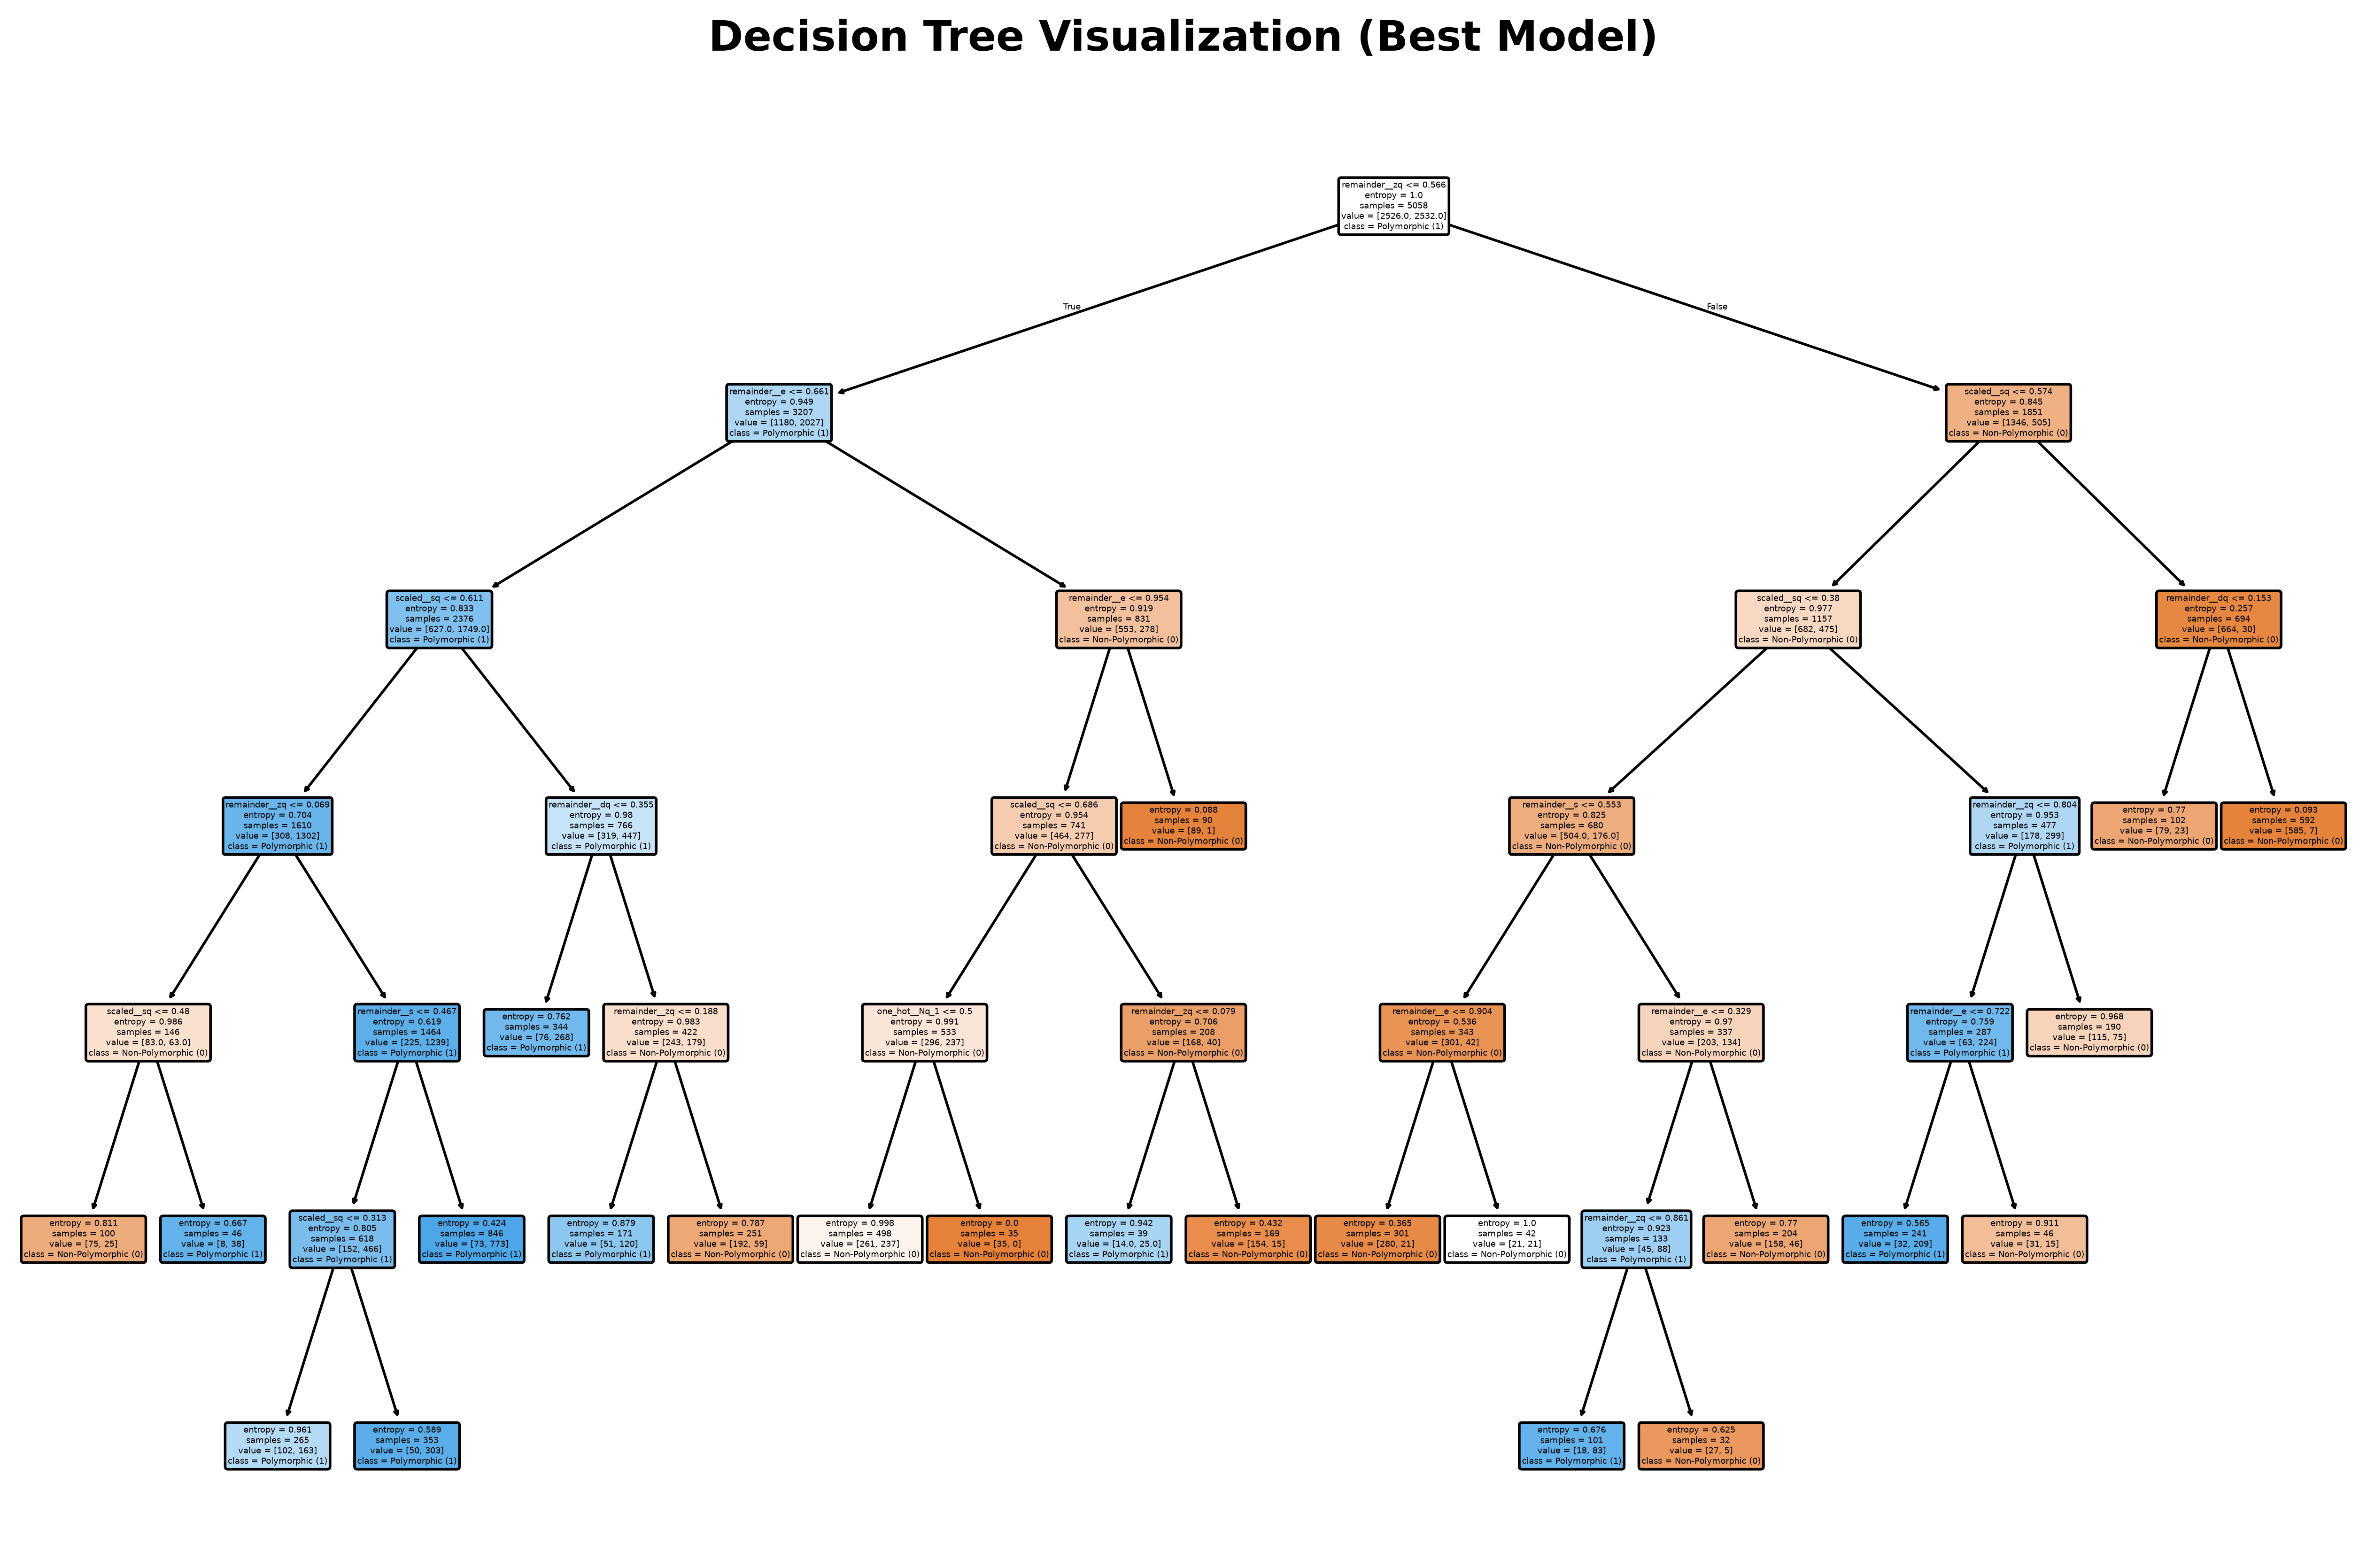

In [394]:
### --- Plot the Decision Tree --- ###
encoded_feature_names = ct.get_feature_names_out() # Get the feature names after the 
                                                   # ColumnTransformer transformation.
# Plot figures.
plt.figure(figsize = (16, 10), dpi = 400)

# Add tree in figure.
plot_tree(
    best_model_dt, 
    feature_names = encoded_feature_names, 
    class_names = ['Non-Polymorphic (0)', 'Polymorphic (1)'],
    filled = True,          # Colors nodes by majority class
    rounded = True,         # Rounds the node boxes for a clean look
)

# Display figure and title.
plt.title("Decision Tree Visualization (Best Model)", fontsize = 16, fontweight = 'bold', pad = 20)
plt.show()

We have now obtain a very **decent decision tree** and all of that with a very **decent accuracy.** That is definitely giving us a **solid biological interpretation** of our model and understanding of how it works. However, we should **keep going** just to see how much more of the accuracy we can explain with **more complex models**, such as the Random Forest, XGBoost or Multilayer Perceptron. But for now, let's plot our **confusion matrix and ROC curve.**

### **Confusion Matrix**

Here is our **model's confusion matrix:**

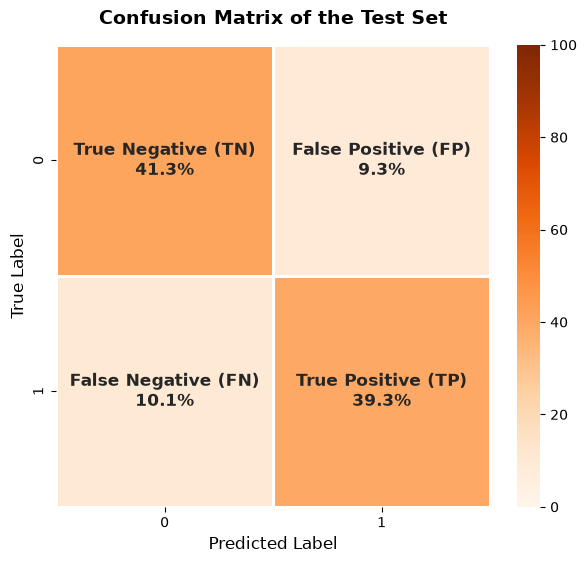

In [395]:
### --- Confusion Matrix for Decision Tree --- ###
plot_confusion_matrix(model = best_model_dt, X_set = X_test, y_set = y_test, type_of_set = "Test")

As we can see on our confusion matrix, our **accuracy improved drastically**. We now are **classsifying correctly four times out of five**. 

### **ROC Plotting**
Let's now plot the **ROC:**

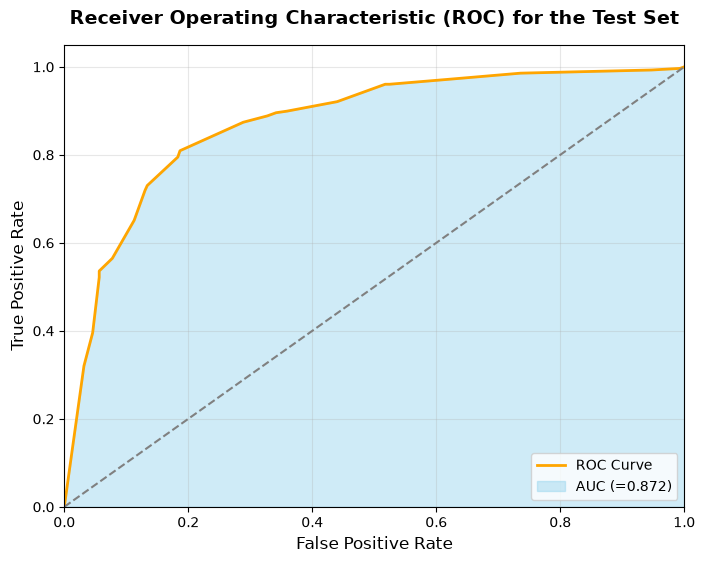

In [396]:
### --- ROC Curve for Decision Tree--- ###
plot_roc(model = best_model_dt, X_set = X_test, y_set = y_test, type_of_set = "Test")

<div class='alert alert-block alert-info'>
<b>Decision Tree Synthesis:</b> As we have been able to witness, the decision tree already does a very decent job at understanding the relationship of our features to the polymorphism classification, by displaying an accuracy of 80%. An advantage of this model is that it is what we call a "whitebox model". So, from a biological standpoint, this is a great model to understand what is happening. Still, we shall progress with more complex ones, that are less interpretable, to see how much we can increase our accuracy. Nonetheless this is great news from an understanding perspective.
</div>

## **Random Forest**

Let's now fit directly a **tuned random forest**, which is an ensemble of decision tree. We will start immediatly using cross validation, since they **tend to overfit** (*a default random forest was tried and overfit as expected*). With a bit of search, we found the **most reasonable hyperparameter ranges**. The **final accuracy** that we obtained the test set was of **86%** after reducing the overfit as much as we could.

In [397]:
### --- Best Random Forest --- ###

### --- Hyperparameter Tuning --- ###
# Define a hyperparameter space that restricts tree complexity.
param_dist = {
    'n_estimators': [50, 100, 200, 300],
    'max_depth': range(1,8),                       # Limiting depth stops memorization
    'min_samples_split': [3, 5, 10, 20, 50],       # Requires more samples to split a node
    'min_samples_leaf': [2, 5, 10, 20],            # Prevents leaves from having tiny, hyper-specific groups
    'max_features': ['sqrt', 'log2', 0.5],         # Subsets features per tree to add diversity
    'bootstrap': [True]
}

# Let's randomly search the hyperparameter space.
rf_base = RandomForestClassifier(random_state = random_seed) # Default RF.
rf_opt = RandomizedSearchCV(
    estimator = rf_base,
    param_distributions = param_dist,
    n_iter = 20,
    cv = 5,
    scoring = 'accuracy',
    random_state = random_seed,
    n_jobs = -1 # Uses all available CPU cores.
)

# Fit the random search.
print("------ Running Randomized Search for Random Forest ------")
search = rf_opt.fit(X_train, y_train['polymorphic'])
best_rf_model = search.best_estimator_ # Best model.
best_rf_params = search.best_params_   # Best hyperparameters set.
print(f"\nBest Hyperparameters Found: {best_rf_params}\n")

### --- Accuracies on Train, Cross-Validation, and Test Sets --- ###
train_acc = accuracy_score(y_train, best_rf_model.predict(X_train)) # Whole traing set accuracy.
CVval_acc = search.best_score_                                      # Best cross validation accuracy.
test_acc  = accuracy_score(y_test, best_rf_model.predict(X_test))   # Testing set accuracy.

print('------ Set Accuracies for RF ------')
print(f'Train Accuracy:              {train_acc:.4f}')
print(f'Cross-validation Accuracy:   {CVval_acc:.4f}')
print(f'Test Accuracy:               {test_acc:.4f}\n')

------ Running Randomized Search for Random Forest ------

Best Hyperparameters Found: {'n_estimators': 100, 'min_samples_split': 3, 'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': 7, 'bootstrap': True}

------ Set Accuracies for RF ------
Train Accuracy:              0.9057
Cross-validation Accuracy:   0.8466
Test Accuracy:               0.8630



We have now obtain a very **good random forest** and all of that with a very **good accuracy, increasing it by 6%.** Let's plot our **confusion matrix, ROC curve and in addition let's do a feature importance plot.** This will allow us to know what the model considers as an **important feature for classification.** Though, we loose some biological intution compared to a decision tree, since it no longer tells us how the feature is used. Nonetheless, let's do this!!

### **Confusion Matrix**

Here is our **model's confusion matrix:**

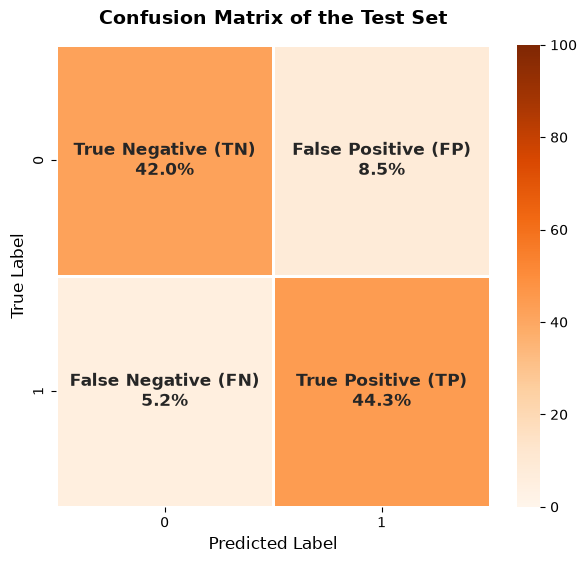

In [398]:
### --- Confusion Matrix for Random Forest --- ###
plot_confusion_matrix(model = best_rf_model, X_set = X_test, y_set = y_test, type_of_set = "Test")

As we can see on our confusion matrix, our **accuracy improved again**. We now are **classsifying correctly 86% of the time**. 

### **ROC Plotting**
Let's now plot the **ROC:**

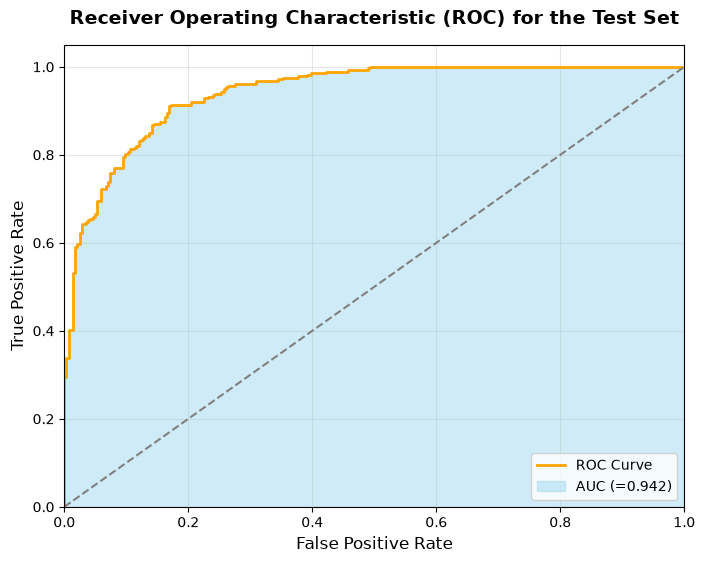

In [399]:
### --- ROC Curve for Random Forest --- ###
plot_roc(model = best_rf_model, X_set = X_test, y_set = y_test, type_of_set = "Test")

As seen with the confusion matrix, we can already tell **our model is much better** than what we started with and it is **still improving** so far.

### **Feature Importance Plot**
Here, we are plotting our **feature importance plot**. Allowing us to assess what features come in to be relevant for the model to classify. We can do this plot because our **features** are nearly perfectly **uncorrelated**.

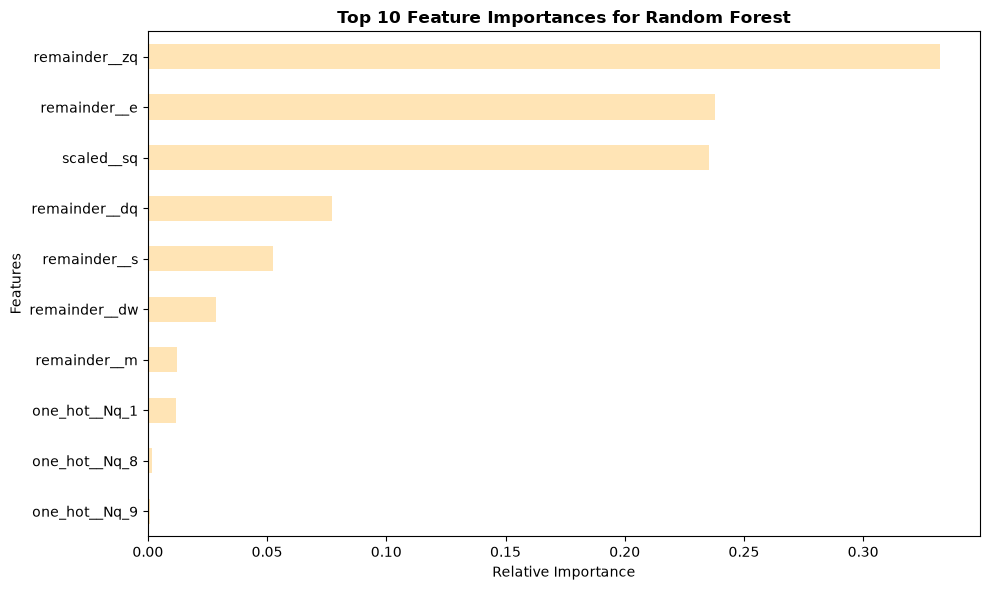

In [400]:
### --- Feature Importance Plot for Random Forest --- ###
feat_imp_plot(preprocess = ct, model = best_rf_model, model_name = 'Random Forest')

<div class='alert alert-block alert-info'>
<b>Random Forest Synthesis:</b> As we have been able to witness, the random forest improved our accuracy by 6%. Yet, what we gained in accuracy, we lost in biological sense, since we are left only with a feature plot now. 
</div>

### **XGBoost**
Let's try to do an XGBoost (eXtreme Gradient Boosting). It is again using trees but implement a gradient boosted framework in those. It sometimes performs better than a simple random forest.

In [401]:
### --- Best eXtreme Gradient Boosting --- ###

### --- Hyperparameter Tuning --- ###
# Define the hyperparameter search space for XGBoost.
param_dist_xgb = {
    'n_estimators': [300, 500, 1000],
    'max_depth': range(1,8),                    # Depth of sequential trees.
    'learning_rate': [0.01, 0.02, 0.03],        # Step size shrinkage to prevent overfitting.
    'subsample': [0.5, 0.6, 0.7],               # Fraction of samples used per tree.
    'colsample_bytree': [0.5, 0.6, 0.7],        # Fraction of features used per tree.
    'min_child_weight': [8, 9, 10],             # Minimum sum of instance weight needed in a child.
    'reg_alpha': [0, 5],                        # L1 regularization (encourages sparsity).
    'reg_lambda': [0, 5]                        # L2 regularization (smooths weights).
}

# Let's randomly search the hyperparameter space.
xgb_base = XGBClassifier(random_state = random_seed, eval_metric = 'logloss')
xgb_opt = RandomizedSearchCV(
    estimator = xgb_base,
    param_distributions = param_dist_xgb,
    n_iter = 20,
    cv = 5,
    scoring = 'accuracy',
    random_state = random_seed,
    n_jobs = -1
)

# Fit the random search.
print("------ Running Randomized Search for XGBoost ------")
search_xgb = xgb_opt.fit(X_train, y_train['polymorphic'])
best_xgb_model = search_xgb.best_estimator_ # Best model.
best_xgb_params = search_xgb.best_params_   # Best hyperparameters set.
print(f"\nBest Hyperparameters Found: {best_xgb_params}\n")

### --- Accuracies on Train, Cross-Validation, and Test Sets --- ###
train_acc = accuracy_score(y_train['polymorphic'], best_xgb_model.predict(X_train)) # Whole traing set accuracy.
CVval_acc = search.best_score_                                                      # Best cross validation accuracy.
test_acc  = accuracy_score(y_test['polymorphic'], best_xgb_model.predict(X_test))   # Testing set accuracy.

print('------ Tuned Set Accuracies for XGB------')
print(f'Train Accuracy:                    {train_acc:.4f}')
print(f'Cross validation Accuracy:         {CVval_acc:.4f}')
print(f'Test Accuracy:                     {test_acc:.4f}\n')

------ Running Randomized Search for XGBoost ------

Best Hyperparameters Found: {'subsample': 0.6, 'reg_lambda': 5, 'reg_alpha': 0, 'n_estimators': 500, 'min_child_weight': 10, 'max_depth': 5, 'learning_rate': 0.03, 'colsample_bytree': 0.6}

------ Tuned Set Accuracies for XGB------
Train Accuracy:                    0.9296
Cross validation Accuracy:         0.8466
Test Accuracy:                     0.9004



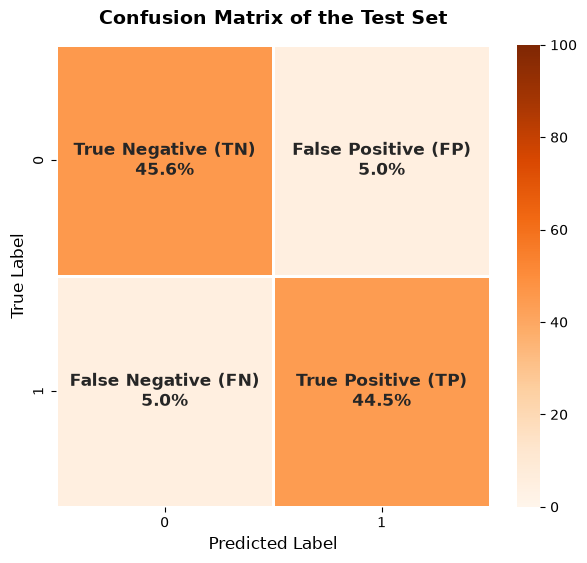

In [402]:
### --- Confusion Matrix for XGBoost --- ###
plot_confusion_matrix(model = best_xgb_model, X_set = X_test, y_set = y_test, type_of_set = "Test")

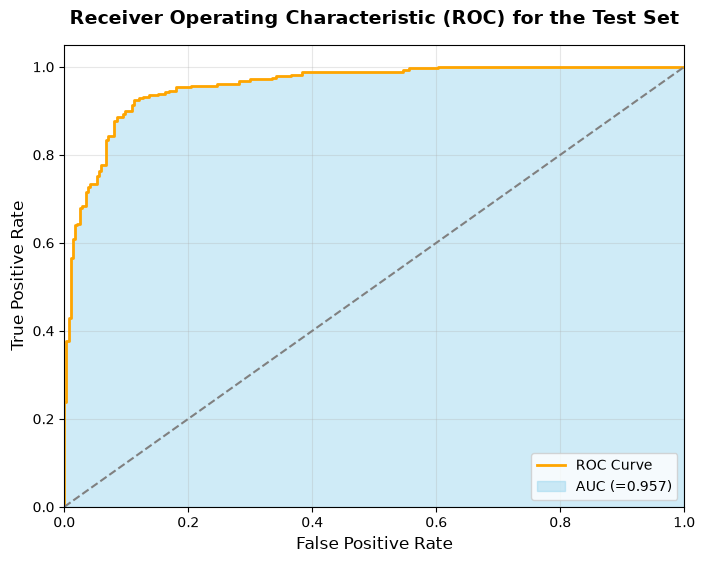

In [403]:
### --- ROC Curve for XGBoost --- ###
plot_roc(model = best_xgb_model, X_set = X_test, y_set = y_test, type_of_set = "Test")

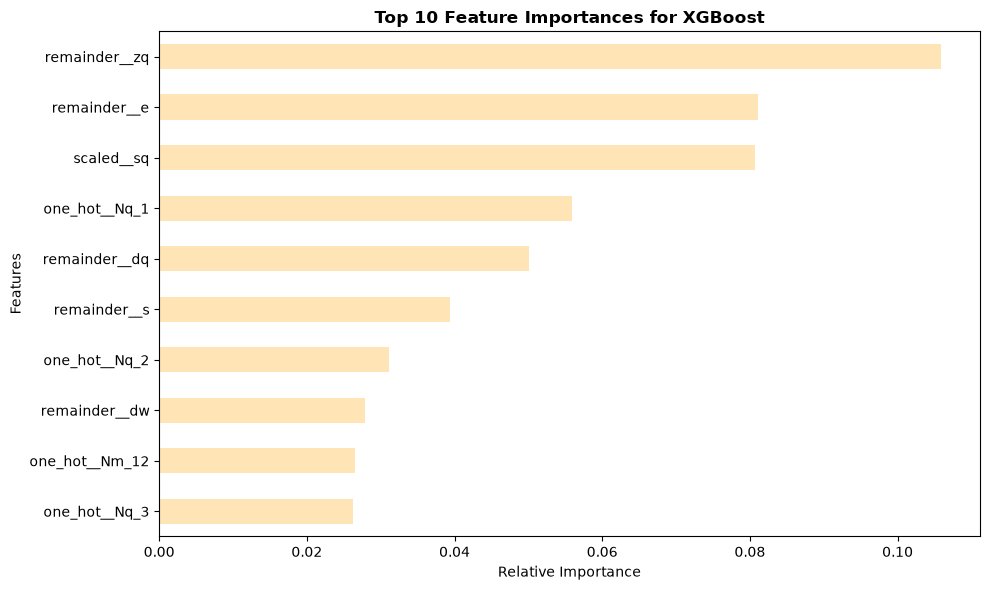

In [404]:
### --- Feature Importance Plot for XGBoost --- ###
feat_imp_plot(preprocess = ct, model = best_xgb_model, model_name = 'XGBoost')

## **Multilayer Perceptron**


In [410]:
### --- Best Multilayer Perceptron --- ###

### --- Hyperparameter Tuning --- ###
# Define the hyperparameter search space for the MLP.
param_dist_mlp = {
    'hidden_layer_sizes': [(30,), (50,), (100,), (50, 25), 
                           (100, 50), (100, 100)],           # Network architecture.
    'activation': ['relu', 'tanh'],                          # Activation functions.
    'alpha': [0.00001, 0.0001, 0.001, 0.01, 0.1, 1.0],       # L2 regularization strength (prevents overfitting).
    'learning_rate_init': [0.0001, 0.001, 0.01, 0.05],       # Initial learning rate.
    'max_iter': [500, 800],                                  # Max training epochs.
    'solver': ['adam', 'sgd']                                # Optimizers.
}

# Let's randomly search the hyperparameter space.
mlp_base = MLPClassifier(random_state = random_seed, early_stopping = True)
mlp_opt = RandomizedSearchCV(
    estimator = mlp_base,
    param_distributions = param_dist_mlp,
    n_iter = 30,
    cv = 5,
    scoring = 'accuracy',
    random_state = random_seed,
    n_jobs = -1
)

# Fit the random search.
print("------ Running Randomized Search for Multilayer Perceptron ------")
search_mlp = mlp_opt.fit(X_train, y_train['polymorphic'])
best_mlp_model = search_mlp.best_estimator_ # Best model.
best_mlp_params = search_mlp.best_params_   # Best hyperparameters set.
print(f"\nBest Hyperparameters Found: {best_mlp_params}\n")

### --- Accuracies on Train, Cross-Validation, and Test Sets --- ###
train_acc = accuracy_score(y_train['polymorphic'], best_mlp_model.predict(X_train)) # Whole traing set accuracy.
CVval_acc = search.best_score_                                                      # Best cross validation accuracy.
test_acc  = accuracy_score(y_test['polymorphic'], best_mlp_model.predict(X_test))   # Testing set accuracy.

print('------ Set Accuracies for MLP------')
print(f'Train Accuracy:              {train_acc:.4f}')
print(f'Validation Accuracy:         {CVval_acc:.4f}')
print(f'Test Accuracy:               {test_acc:.4f}\n')

------ Running Randomized Search for Multilayer Perceptron ------

Best Hyperparameters Found: {'solver': 'adam', 'max_iter': 500, 'learning_rate_init': 0.01, 'hidden_layer_sizes': (50, 25), 'alpha': 0.1, 'activation': 'tanh'}

------ Set Accuracies for MLP------
Train Accuracy:              0.8885
Validation Accuracy:         0.8466
Test Accuracy:               0.8470



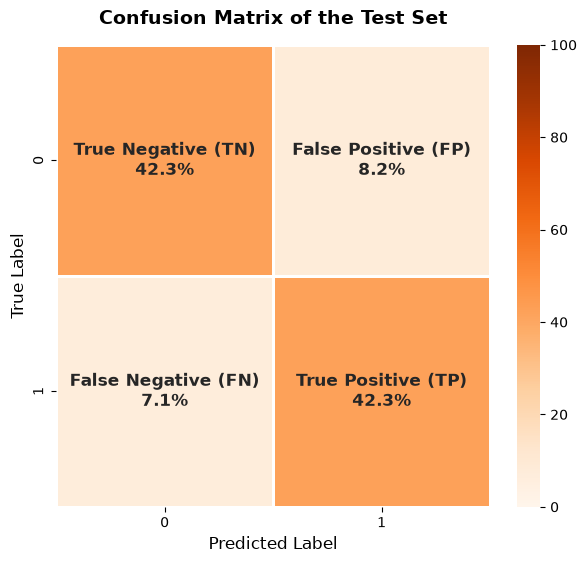

In [412]:
### --- Confusion Matrix for Multilayer Perceptron --- ###
plot_confusion_matrix(model = best_mlp_model, X_set = X_test, y_set = y_test, type_of_set = "Test")

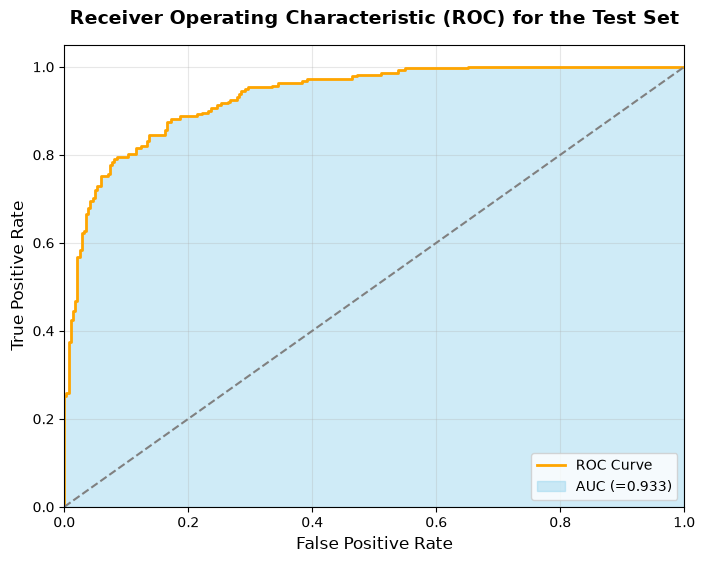

In [413]:
### --- ROC Curve for Multilayer Perceptron --- ###
plot_roc(model = best_mlp_model, X_set = X_test, y_set = y_test, type_of_set = "Test")

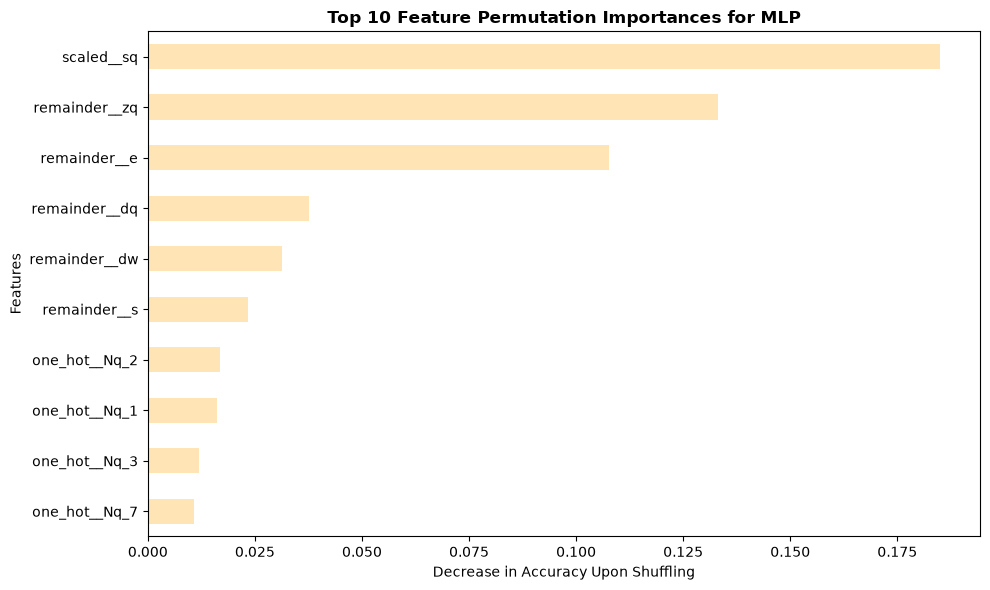

In [ ]:
### --- Feature Permutation Importance Plot for Multilayer Perceptron --- ###

# Create X_test_df from the existing X_test to later permutate it.
feature_names = ct.get_feature_names_out()
if hasattr(X_test, "toarray"):
    X_test_df = pd.DataFrame(X_test.toarray(), columns=feature_names)
else:
    X_test_df = pd.DataFrame(X_test, columns=feature_names)

# Calculate permutation importance on the test set.
result = permutation_importance(
    best_mlp_model, 
    X_test_df, 
    y_test['polymorphic'], 
    n_repeats = 10, 
    random_state= random_seed, 
    n_jobs = -1
)

# Put the results into a pandas Series and plot.
perm_importances = pd.Series(result.importances_mean, index = feature_names)

# Plot the top 10 features, with title and labels.
plt.figure(figsize = (10, 6))
perm_importances.nlargest(10).sort_values().plot(kind = 'barh', color = 'moccasin')
plt.title('Top 10 Feature Permutation Importances for MLP', fontweight = 'bold')
plt.xlabel('Decrease in Accuracy Upon Shuffling')
plt.ylabel('Features')
plt.tight_layout()
plt.show()